<a href="https://colab.research.google.com/github/Shuru311/IDS2023Lab/blob/main/BAA_5123_AI_Credit_Scoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bianca - Member 1

In [ ]:
# ============================================================
# STEP 1: IMPORT LIBRARIES AND SETUP
# ============================================================

# Standard Python libraries
from pathlib import Path
import io
import hashlib
import json
import requests

# Data analysis and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Colab and notebook utilities
from IPython.display import display
from google.colab import files

# Statistical analysis
from scipy.stats import chi2_contingency

# Data splitting and model selection
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)

# Preprocessing and pipelines
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Evaluation metrics and plots
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.calibration import CalibrationDisplay

# Reproducibility
SEED = 42

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.3f}"
)

sns.set_theme(
    style="whitegrid",
    palette=["#167D9A", "#DA7655"]
)

# Member 1 output folders
OUTPUT = Path("german_credit_outputs")
FIGURE_DIR = OUTPUT / "figures"

OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

def save_table(
    data,
    name=None,
    index=True
):
    """Display an analysis table."""
    display(data)

def finish_plot(name):
    """Save, display and close a Member 1 figure."""

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"{name}.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All libraries and output folders are ready.")

All libraries and output folders are ready.


In [ ]:
# ============================================================
# STEP 2: DOWNLOAD AND LOAD THE OFFICIAL UCI DATASET
# ============================================================

official_url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/statlog/german/german.data"
)

response = requests.get(
    official_url,
    timeout=30
)

response.raise_for_status()

data_bytes = response.content

column_names = [
    "checking_status",
    "duration_months",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_status",
    "employment_duration",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_duration",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_class"
]

df_raw = pd.read_csv(
    io.BytesIO(data_bytes),
    sep=r"\s+",
    header=None,
    names=column_names
)

source_sha256 = hashlib.sha256(
    data_bytes
).hexdigest()

print("Data downloaded directly from:")
print(official_url)

print("\nDataset shape:", df_raw.shape)

print("\nSource SHA-256:")
print(source_sha256)

display(df_raw.head())

Data downloaded directly from:
https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data

Dataset shape: (1000, 21)

Source SHA-256:
b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871


,checking_status,duration_months,credit_history,purpose,credit_amount,savings_status,employment_duration,installment_rate,personal_status_sex,other_debtors,residence_duration,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [ ]:
# ============================================================
# STEP 2A: VERIFY SOURCE FILE AGAINST OFFICIAL UCI COPY
# ============================================================

EXPECTED_UCI_SHA256 = (
    "b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871"
)

integrity_match = (
    source_sha256 == EXPECTED_UCI_SHA256
)

integrity_verification = pd.DataFrame({
    "Check": [
        "Expected official SHA-256",
        "Downloaded file SHA-256"
    ],
    "Value": [
        EXPECTED_UCI_SHA256,
        source_sha256
    ]
})

display(integrity_verification)

print("Checksum match:", integrity_match)

assert integrity_match, (
    "The downloaded file checksum differs from "
    "the verified UCI source checksum."
)

print(
    "PASS: The downloaded dataset matches the "
    "verified official UCI file."
)

,Check,Value
0,Expected official SHA-256,b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc...
1,Downloaded file SHA-256,b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc...


Checksum match: True
PASS: The downloaded dataset matches the verified official UCI file.


In [ ]:
# ============================================================
# STEP 3: VALIDATE DATASET STRUCTURE AND VALUES
# ============================================================

assert df_raw.shape == (1000, 21), (
    f"Expected (1000, 21), received {df_raw.shape}"
)

assert df_raw.columns.is_unique, "Column names are not unique."

assert df_raw["credit_class"].isin([1, 2]).all(), (
    "Unexpected target values."
)

assert df_raw["duration_months"].gt(0).all(), (
    "Duration contains non-positive values."
)

assert df_raw["credit_amount"].gt(0).all(), (
    "Credit amount contains non-positive values."
)

assert df_raw["age"].between(18, 100).all(), (
    "Age contains implausible values."
)

assert df_raw["installment_rate"].between(1, 4).all()
assert df_raw["residence_duration"].between(1, 4).all()
assert df_raw["existing_credits"].ge(1).all()
assert df_raw["dependents"].ge(1).all()

quality_table = pd.DataFrame({
    "Data_type": df_raw.dtypes.astype(str),
    "Missing_count": df_raw.isna().sum(),
    "Missing_percent": df_raw.isna().mean() * 100,
    "Unique_values": df_raw.nunique(dropna=False)
})

save_table(
    quality_table,
    "01_source_data_quality"
)

print("Missing cells:", int(df_raw.isna().sum().sum()))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
print("Dataset validation completed.")

# Verify documented UCI target distribution.
target_counts = (
    df_raw["credit_class"]
    .value_counts()
    .sort_index()
)

observed_good_risk = int(
    target_counts.get(1, 0)
)

observed_bad_risk = int(
    target_counts.get(2, 0)
)

verification_summary = pd.DataFrame({
    "Verification": [
        "Observations",
        "Predictor features",
        "Target columns",
        "Good-risk cases",
        "Bad-risk cases"
    ],
    "Expected": [
        1000,
        20,
        1,
        700,
        300
    ],
    "Observed": [
        df_raw.shape[0],
        df_raw.shape[1] - 1,
        1,
        observed_good_risk,
        observed_bad_risk
    ]
})

verification_summary["Result"] = np.where(
    verification_summary["Expected"]
    == verification_summary["Observed"],
    "Pass",
    "Fail"
)

display(verification_summary)

assert observed_good_risk == 700
assert observed_bad_risk == 300

print(
    "PASS: Dataset structure and target distribution "
    "match the UCI documentation."
)

,Data_type,Missing_count,Missing_percent,Unique_values
checking_status,object,0,0.000,4
duration_months,int64,0,0.000,33
credit_history,object,0,0.000,5
purpose,object,0,0.000,10
credit_amount,int64,0,0.000,921
savings_status,object,0,0.000,5
employment_duration,object,0,0.000,5
installment_rate,int64,0,0.000,4
personal_status_sex,object,0,0.000,4
other_debtors,object,0,0.000,3


Missing cells: 0
Exact duplicate rows: 0
Dataset validation completed.


,Verification,Expected,Observed,Result
0,Observations,1000,1000,Pass
1,Predictor features,20,20,Pass
2,Target columns,1,1,Pass
3,Good-risk cases,700,700,Pass
4,Bad-risk cases,300,300,Pass


PASS: Dataset structure and target distribution match the UCI documentation.


In [ ]:
# ============================================================
# STEP 4: VALIDATE CATEGORICAL CODES
# ============================================================

allowed_categories = {
    "checking_status": {"A11", "A12", "A13", "A14"},
    "credit_history": {"A30", "A31", "A32", "A33", "A34"},
    "purpose": {
        "A40", "A41", "A42", "A43", "A44",
        "A45", "A46", "A47", "A48", "A49", "A410"
    },
    "savings_status": {"A61", "A62", "A63", "A64", "A65"},
    "employment_duration": {
        "A71", "A72", "A73", "A74", "A75"
    },
    "personal_status_sex": {
        "A91", "A92", "A93", "A94", "A95"
    },
    "other_debtors": {"A101", "A102", "A103"},
    "property": {"A121", "A122", "A123", "A124"},
    "other_installment_plans": {"A141", "A142", "A143"},
    "housing": {"A151", "A152", "A153"},
    "job": {"A171", "A172", "A173", "A174"},
    "telephone": {"A191", "A192"},
    "foreign_worker": {"A201", "A202"}
}

for column, valid_values in allowed_categories.items():
    observed_values = set(df_raw[column].dropna().unique())

    unexpected = observed_values - valid_values

    assert not unexpected, (
        f"Unexpected codes in {column}: {unexpected}"
    )

print("All categorical codes match the UCI documentation.")

All categorical codes match the UCI documentation.


In [ ]:
# ============================================================
# STEP 5: CREATE IDENTIFIER, TARGET AND AUDIT VARIABLES
# ============================================================

df = df_raw.copy(deep=True)

# Create a stable row identifier.
df.insert(
    0,
    "customer_id",
    np.arange(1, len(df) + 1)
)

# Original target:
# 1 = good credit risk
# 2 = bad credit risk
#
# Clean modelling target:
# 0 = good credit risk
# 1 = bad credit risk

df["bad_risk"] = df["credit_class"].map({
    1: 0,
    2: 1
}).astype(int)

df["risk_label"] = df["bad_risk"].map({
    0: "Good risk",
    1: "Bad risk"
})

# Derive sex from the combined personal-status/sex field.
sex_map = {
    "A91": "male",
    "A92": "female",
    "A93": "male",
    "A94": "male",
    "A95": "female"
}

df["sex_audit"] = df["personal_status_sex"].map(sex_map)
# Derive the personal-status grouping from original Attribute 9.

personal_status_map = {
    "A91": "divorced_or_separated",
    "A92": "divorced_separated_or_married",
    "A93": "single",
    "A94": "married_or_widowed",
    "A95": "single"
}

df["personal_status_group"] = (
    df["personal_status_sex"]
    .map(personal_status_map)
)

assert df["personal_status_group"].notna().all()

# Create age groups for later sensitivity analysis.
df["age_group_audit"] = pd.cut(
    df["age"],
    bins=[0, 24, 44, np.inf],
    labels=[
        "under_25",
        "25_to_44",
        "45_and_over"
    ],
    right=True
)

assert df["customer_id"].is_unique
assert df["bad_risk"].notna().all()
assert df["sex_audit"].notna().all()
assert df["age_group_audit"].notna().all()

target_summary = pd.DataFrame({
    "Count": df["risk_label"].value_counts(),
    "Percent": df["risk_label"].value_counts(normalize=True) * 100
})

save_table(
    target_summary,
    "02_full_data_target_distribution"
)

print("Identifier, target and audit variables created.")

,Count,Percent
risk_label,,
Good risk,700,70.000
Bad risk,300,30.000


Identifier, target and audit variables created.


In [ ]:
# ============================================================
# STEP 6: CONVERT SOURCE CODES TO READABLE LABELS
# ============================================================

category_mappings = {
    "checking_status": {
        "A11": "less_than_0_DM",
        "A12": "0_to_less_than_200_DM",
        "A13": "at_least_200_DM",
        "A14": "no_checking_account"
    },
    "credit_history": {
        "A30": "no_credit_or_all_paid",
        "A31": "all_bank_credits_paid",
        "A32": "existing_credits_paid_duly",
        "A33": "payment_delay_in_past",
        "A34": "critical_account_or_other_credits"
    },
    "purpose": {
        "A40": "new_car",
        "A41": "used_car",
        "A42": "furniture_equipment",
        "A43": "radio_television",
        "A44": "domestic_appliances",
        "A45": "repairs",
        "A46": "education",
        "A47": "vacation",
        "A48": "retraining",
        "A49": "business",
        "A410": "other"
    },
    "savings_status": {
        "A61": "less_than_100_DM",
        "A62": "100_to_less_than_500_DM",
        "A63": "500_to_less_than_1000_DM",
        "A64": "at_least_1000_DM",
        "A65": "unknown_or_no_savings"
    },
    "employment_duration": {
        "A71": "unemployed",
        "A72": "less_than_1_year",
        "A73": "1_to_less_than_4_years",
        "A74": "4_to_less_than_7_years",
        "A75": "at_least_7_years"
    },
    "personal_status_sex": {
        "A91": "male_divorced_or_separated",
        "A92": "female_divorced_separated_or_married",
        "A93": "male_single",
        "A94": "male_married_or_widowed",
        "A95": "female_single"
    },
    "other_debtors": {
        "A101": "none",
        "A102": "co_applicant",
        "A103": "guarantor"
    },
    "property": {
        "A121": "real_estate",
        "A122": "savings_agreement_or_life_insurance",
        "A123": "car_or_other_property",
        "A124": "unknown_or_no_property"
    },
    "other_installment_plans": {
        "A141": "bank",
        "A142": "stores",
        "A143": "none"
    },
    "housing": {
        "A151": "rent",
        "A152": "own",
        "A153": "free"
    },
    "job": {
        "A171": "unemployed_or_unskilled_nonresident",
        "A172": "unskilled_resident",
        "A173": "skilled_employee_or_official",
        "A174": "management_self_employed_or_highly_qualified"
    },
    "telephone": {
        "A191": "none",
        "A192": "registered_telephone"
    },
    "foreign_worker": {
        "A201": "yes",
        "A202": "no"
    }
}

for column, mapping in category_mappings.items():
    if column in df.columns:
        # Save raw codes into dedicated column
        df[f"{column}_code"] = df[column]
        # Map values to readable labels
        df[column] = df[column].map(mapping)

        assert df[column].notna().all(), (
            f"Mapping created missing values in {column}"
        )

print("Categorical codes converted to readable labels safely.")
display(df.head())

Categorical codes converted to readable labels safely.


,customer_id,checking_status,duration_months,credit_history,purpose,credit_amount,savings_status,employment_duration,installment_rate,personal_status_sex,other_debtors,residence_duration,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_class,bad_risk,risk_label,sex_audit,personal_status_group,age_group_audit,checking_status_code,credit_history_code,purpose_code,savings_status_code,employment_duration_code,personal_status_sex_code,other_debtors_code,property_code,other_installment_plans_code,housing_code,job_code,telephone_code,foreign_worker_code
0,1,less_than_0_DM,6,critical_account_or_other_credits,radio_television,1169,unknown_or_no_savings,at_least_7_years,4,male_single,none,4,real_estate,67,none,own,2,skilled_employee_or_official,1,registered_telephone,yes,1,0,Good risk,male,single,45_and_over,A11,A34,A43,A65,A75,A93,A101,A121,A143,A152,A173,A192,A201
1,2,0_to_less_than_200_DM,48,existing_credits_paid_duly,radio_television,5951,less_than_100_DM,1_to_less_than_4_years,2,female_divorced_separated_or_married,none,2,real_estate,22,none,own,1,skilled_employee_or_official,1,none,yes,2,1,Bad risk,female,divorced_separated_or_married,under_25,A12,A32,A43,A61,A73,A92,A101,A121,A143,A152,A173,A191,A201
2,3,no_checking_account,12,critical_account_or_other_credits,education,2096,less_than_100_DM,4_to_less_than_7_years,2,male_single,none,3,real_estate,49,none,own,1,unskilled_resident,2,none,yes,1,0,Good risk,male,single,45_and_over,A14,A34,A46,A61,A74,A93,A101,A121,A143,A152,A172,A191,A201
3,4,less_than_0_DM,42,existing_credits_paid_duly,furniture_equipment,7882,less_than_100_DM,4_to_less_than_7_years,2,male_single,guarantor,4,savings_agreement_or_life_insurance,45,none,free,1,skilled_employee_or_official,2,none,yes,1,0,Good risk,male,single,45_and_over,A11,A32,A42,A61,A74,A93,A103,A122,A143,A153,A173,A191,A201
4,5,less_than_0_DM,24,payment_delay_in_past,new_car,4870,less_than_100_DM,1_to_less_than_4_years,3,male_single,none,4,unknown_or_no_property,53,none,free,2,skilled_employee_or_official,2,none,yes,2,1,Bad risk,male,single,45_and_over,A11,A33,A40,A61,A73,A93,A101,A124,A143,A153,A173,A191,A201


In [ ]:
# ============================================================
# STEP 7: VERIFY CATEGORICAL MAPPINGS
# ============================================================

mapping_results = []

for column, mapping in category_mappings.items():
    code_column = f"{column}_code"

    assert code_column in df.columns, (
        f"Missing column: {code_column}. "
        "Rerun Step 5, then rerun Step 6 once."
    )

    observed_codes = set(df[code_column].dropna().unique())
    recognised_codes = set(mapping.keys())
    unrecognised_codes = observed_codes - recognised_codes
    missing_mapped_labels = int(df[column].isna().sum())

    mapping_results.append({
        "Feature": column,
        "Observed_code_count": len(observed_codes),
        "Unrecognised_codes": (
            ", ".join(sorted(unrecognised_codes))
            if unrecognised_codes
            else "None"
        ),
        "Missing_mapped_labels": missing_mapped_labels
    })

mapping_check = pd.DataFrame(mapping_results)
display(mapping_check)

has_unrecognised_codes = (
    mapping_check["Unrecognised_codes"] != "None"
).any()
total_missing_labels = mapping_check["Missing_mapped_labels"].sum()

assert not has_unrecognised_codes, (
    "Some original UCI codes were not recognised. "
    "Review the Unrecognised_codes column."
)

assert total_missing_labels == 0, (
    "Some readable labels are missing. "
    "Rerun Step 5 and then run Step 6 exactly once."
)

print(
    "PASS: Every observed UCI categorical code "
    "was converted to an official readable label."
)

,Feature,Observed_code_count,Unrecognised_codes,Missing_mapped_labels
0,checking_status,4,None,0
1,credit_history,5,None,0
2,purpose,10,None,0
3,savings_status,5,None,0
4,employment_duration,5,None,0
5,personal_status_sex,4,None,0
6,other_debtors,3,None,0
7,property,4,None,0
8,other_installment_plans,3,None,0
9,housing,3,None,0


PASS: Every observed UCI categorical code was converted to an official readable label.


In [ ]:
# ============================================================
# STEP 8: CREATE AND VERIFY OFFICIAL UCI DESCRIPTIONS
# ============================================================

uci_official_descriptions = {
    "checking_status": {
        "A11": "x < 0 DM",
        "A12": "0 DM <= x < 200 DM",
        "A13": "x >= 200 DM / salary assignments for at least 1 year",
        "A14": "no checking account"
    },
    "credit_history": {
        "A30": "no credits taken / all credits paid back duly",
        "A31": "all credits at this bank paid back duly",
        "A32": "existing credits paid back duly till now",
        "A33": "delay in paying off in the past",
        "A34": "critical account / other credits existing (not at this bank)"
    },
    "purpose": {
        "A40": "car (new)",
        "A41": "car (used)",
        "A42": "furniture/equipment",
        "A43": "radio/television",
        "A44": "domestic appliances",
        "A45": "repairs",
        "A46": "education",
        "A47": "vacation (does not exist in observed data)",
        "A48": "retraining",
        "A49": "business",
        "A410": "others"
    },
    "savings_status": {
        "A61": "x < 100 DM",
        "A62": "100 DM <= x < 500 DM",
        "A63": "500 DM <= x < 1000 DM",
        "A64": "x >= 1000 DM",
        "A65": "unknown / no savings account"
    },
    "employment_duration": {
        "A71": "unemployed",
        "A72": "x < 1 year",
        "A73": "1 year <= x < 4 years",
        "A74": "4 years <= x < 7 years",
        "A75": "x >= 7 years"
    },
    "personal_status_sex": {
        "A91": "male: divorced/separated",
        "A92": "female: divorced/separated/married",
        "A93": "male: single",
        "A94": "male: married/widowed",
        "A95": "female: single"
    },
    "other_debtors": {
        "A101": "none",
        "A102": "co-applicant",
        "A103": "guarantor"
    },
    "property": {
        "A121": "real estate",
        "A122": "building society savings agreement / life insurance",
        "A123": "car or other property, not included in savings account/bonds",
        "A124": "unknown / no property"
    },
    "other_installment_plans": {
        "A141": "bank",
        "A142": "stores",
        "A143": "none"
    },
    "housing": {
        "A151": "rent",
        "A152": "own",
        "A153": "for free"
    },
    "job": {
        "A171": "unemployed / unskilled - non-resident",
        "A172": "unskilled - resident",
        "A173": "skilled employee / official",
        "A174": "management / self-employed / highly qualified employee / officer"
    },
    "telephone": {
        "A191": "none",
        "A192": "yes, registered under the customer's name"
    },
    "foreign_worker": {
        "A201": "yes",
        "A202": "no"
    }
}

df_full_information = df.copy()

for column, description_mapping in uci_official_descriptions.items():
    code_column = f"{column}_code"
    description_column = f"{column}_uci_description"

    assert code_column in df_full_information.columns, (
        f"Missing original-code column: {code_column}. "
        "Rerun Step 5 and Step 6."
    )

    df_full_information[description_column] = (
        df_full_information[code_column].map(description_mapping)
    )

    assert (
        df_full_information[description_column].notna().all()
    ), f"Missing official description for {column}"

# Display the three representations of Purpose.
purpose_reference = (
    df_full_information[
        ["purpose_code", "purpose", "purpose_uci_description"]
    ]
    .drop_duplicates()
    .sort_values("purpose_code")
    .reset_index(drop=True)
)

display(purpose_reference)

# Confirm that A41 and A410 remain separate.
assert (
    df_full_information.loc[
        df_full_information["purpose_code"] == "A41",
        "purpose_uci_description"
    ] == "car (used)"
).all()

assert (
    df_full_information.loc[
        df_full_information["purpose_code"] == "A410",
        "purpose_uci_description"
    ] == "others"
).all()

print("Official UCI descriptions created and verified.")
print("The final CSV will be exported after creating the split.")

,purpose_code,purpose,purpose_uci_description
0,A40,new_car,car (new)
1,A41,used_car,car (used)
2,A410,other,others
3,A42,furniture_equipment,furniture/equipment
4,A43,radio_television,radio/television
5,A44,domestic_appliances,domestic appliances
6,A45,repairs,repairs
7,A46,education,education
8,A48,retraining,retraining
9,A49,business,business


Official UCI descriptions created and verified.
The final CSV will be exported after creating the split.


In [ ]:
# ============================================================
# STEP 9: DEFINE ORIGINAL FEATURE GROUPS
# ============================================================

numeric_features = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_duration",
    "age",
    "existing_credits",
    "dependents"
]

categorical_features = [
    "checking_status",
    "credit_history",
    "purpose",
    "savings_status",
    "employment_duration",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

assert len(numeric_features) == 7
assert len(categorical_features) == 13
assert len(numeric_features + categorical_features) == 20

feature_dictionary = pd.DataFrame({
    "Feature": numeric_features + categorical_features,
    "Type": (
        ["Numerical"] * len(numeric_features)
        + ["Categorical"] * len(categorical_features)
    )
})

save_table(
    feature_dictionary,
    "03_feature_dictionary",
    index=False
)

print("Confirmed: 7 numerical + 13 categorical = 20 predictors.")

,Feature,Type
0,duration_months,Numerical
1,credit_amount,Numerical
2,installment_rate,Numerical
3,residence_duration,Numerical
4,age,Numerical
5,existing_credits,Numerical
6,dependents,Numerical
7,checking_status,Categorical
8,credit_history,Categorical
9,purpose,Categorical


Confirmed: 7 numerical + 13 categorical = 20 predictors.


In [ ]:
# ============================================================
# STEP 10: CREATE SHARED TRAIN-TEST SPLIT
# ============================================================

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=SEED,
    stratify=df["bad_risk"]
)

df["split"] = "train"
df.loc[test_idx, "split"] = "test"

train_df = df.loc[train_idx].copy()
test_df = df.loc[test_idx].copy()

assert set(train_df["customer_id"]).isdisjoint(
    set(test_df["customer_id"])
)

assert len(train_df) + len(test_df) == len(df)

split_summary = (
    df.groupby("split")
      .agg(
          Customers=("customer_id", "size"),
          Good_risk=("bad_risk", lambda x: int((x == 0).sum())),
          Bad_risk=("bad_risk", "sum"),
          Bad_risk_rate=("bad_risk", "mean")
      )
)

split_summary["Bad_risk_rate_percent"] = (
    split_summary["Bad_risk_rate"] * 100
)

save_table(
    split_summary,
    "04_split_summary"
)

print("Training customers:", len(train_df))
print("Test customers:", len(test_df))

split_manifest = (
    df[
        [
            "customer_id",
            "split"
        ]
    ]
    .sort_values("customer_id")
    .reset_index(drop=True)
)

print("Shared split created and retained in memory.")

,Customers,Good_risk,Bad_risk,Bad_risk_rate,Bad_risk_rate_percent
split,,,,,
test,200,140,60,0.300,30.000
train,800,560,240,0.300,30.000


Training customers: 800
Test customers: 200
Shared split created and retained in memory.


In [ ]:
# ============================================================
# STEP 11: VERIFY AUDIT-GROUP REPRESENTATION
# ============================================================

sex_split_table = pd.crosstab(
    [df["split"], df["sex_audit"]],
    df["risk_label"],
    margins=True
)

age_split_table = pd.crosstab(
    [df["split"], df["age_group_audit"]],
    df["risk_label"],
    margins=True
)

save_table(
    sex_split_table,
    "05_sex_target_by_split"
)

save_table(
    age_split_table,
    "06_age_target_by_split"
)

print(
    "These tables describe representation only. "
    "They are not approval-rate fairness results."
)

risk_label       Bad risk  Good risk   All
split sex_audit                           
test  female           20         41    61
      male             40         99   139
train female           89        160   249
      male            151        400   551
All                   300        700  1000

risk_label             Bad risk  Good risk   All
split age_group_audit                           
test  under_25               19         20    39
      25_to_44               33         80   113
      45_and_over             8         40    48
train under_25               42         68   110
      25_to_44              156        381   537
      45_and_over            42        111   153
All                         300        700  1000

These tables describe representation only. They are not approval-rate fairness results.


In [ ]:
# ============================================================
# STEP 12: SET TRAINING DATA FOR DETAILED EDA
# ============================================================

eda = train_df.copy()

print(
    "All following distributions, relationships and statistical "
    "tests use training data only."
)

print("EDA sample size:", len(eda))
print("Good risks:", int((eda["bad_risk"] == 0).sum()))
print("Bad risks:", int((eda["bad_risk"] == 1).sum()))

All following distributions, relationships and statistical tests use training data only.
EDA sample size: 800
Good risks: 560
Bad risks: 240


,count,mean,std,min,25%,50%,75%,max,Median,Skewness
duration_months,800.000,20.770,11.817,4.000,12.000,18.000,24.000,60.000,18.000,1.047
credit_amount,800.000,"3,189.591","2,673.547",276.000,"1,353.000","2,317.000","3,933.000","15,945.000","2,317.000",1.826
installment_rate,800.000,2.941,1.124,1.000,2.000,3.000,4.000,4.000,3.000,-0.488
residence_duration,800.000,2.830,1.111,1.000,2.000,3.000,4.000,4.000,3.000,-0.264
age,800.000,35.324,11.045,19.000,27.000,33.000,41.000,75.000,33.000,1.043
existing_credits,800.000,1.407,0.567,1.000,1.000,1.000,2.000,4.000,1.000,1.192
dependents,800.000,1.160,0.367,1.000,1.000,1.000,1.000,2.000,1.000,1.858


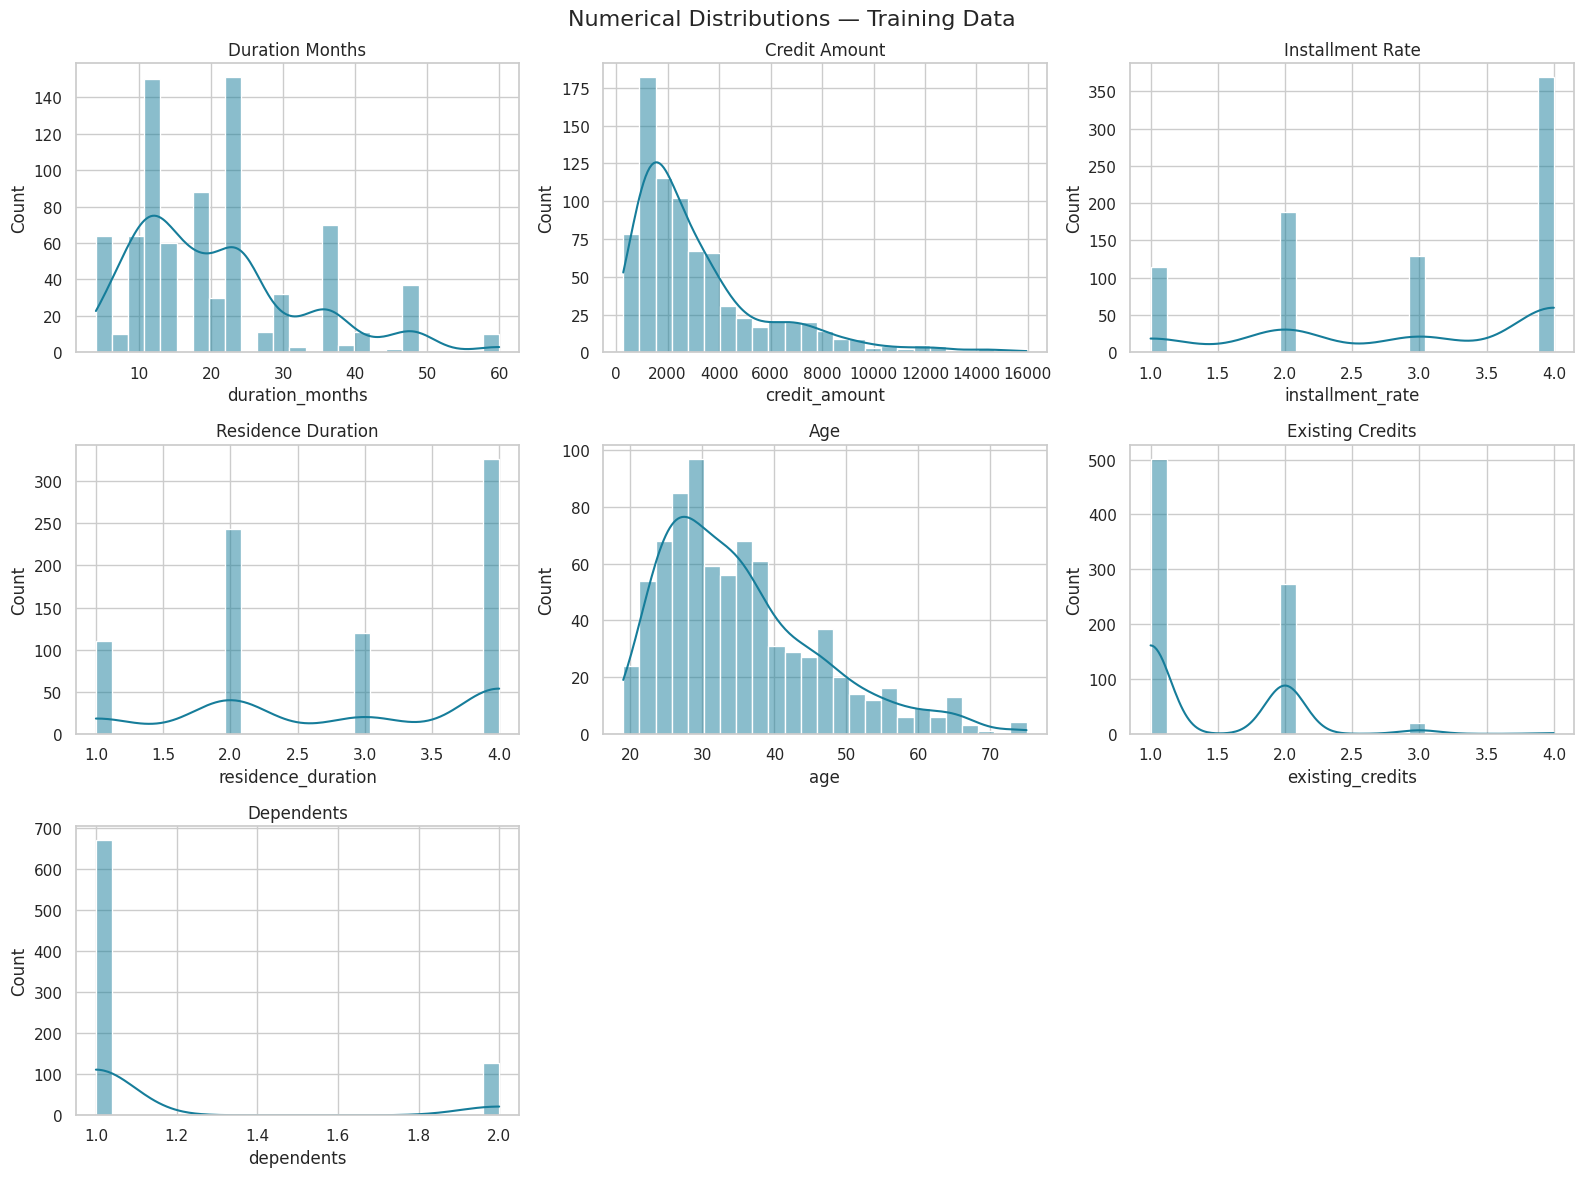

In [ ]:
# ============================================================
# STEP 13: NUMERICAL SUMMARY
# ============================================================

numeric_summary = eda[numeric_features].describe().T

numeric_summary["Median"] = (
    eda[numeric_features].median()
)

numeric_summary["Skewness"] = (
    eda[numeric_features].skew()
)

save_table(
    numeric_summary,
    "07_numerical_summary_train"
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(16, 12)
)

axes = axes.flatten()

for ax, column in zip(axes, numeric_features):
    sns.histplot(
        data=eda,
        x=column,
        bins=25,
        kde=True,
        ax=ax,
        color="#167D9A"
    )

    ax.set_title(
        column.replace("_", " ").title()
    )

for ax in axes[len(numeric_features):]:
    ax.axis("off")

fig.suptitle(
    "Numerical Distributions — Training Data",
    fontsize=16
)

finish_plot("01_numerical_distributions_train")

,Variable,Q1,Q3,IQR,Lower_fence,Upper_fence,Flagged_values
0,duration_months,12.000,24.000,12.000,-6.000,42.000,50
1,credit_amount,"1,353.000","3,933.000","2,580.000","-2,517.000","7,803.000",58
2,installment_rate,2.000,4.000,2.000,-1.000,7.000,0
3,residence_duration,2.000,4.000,2.000,-1.000,7.000,0
4,age,27.000,41.000,14.000,6.000,62.000,25
5,existing_credits,1.000,2.000,1.000,-0.500,3.500,4
6,dependents,1.000,1.000,0.000,1.000,1.000,128


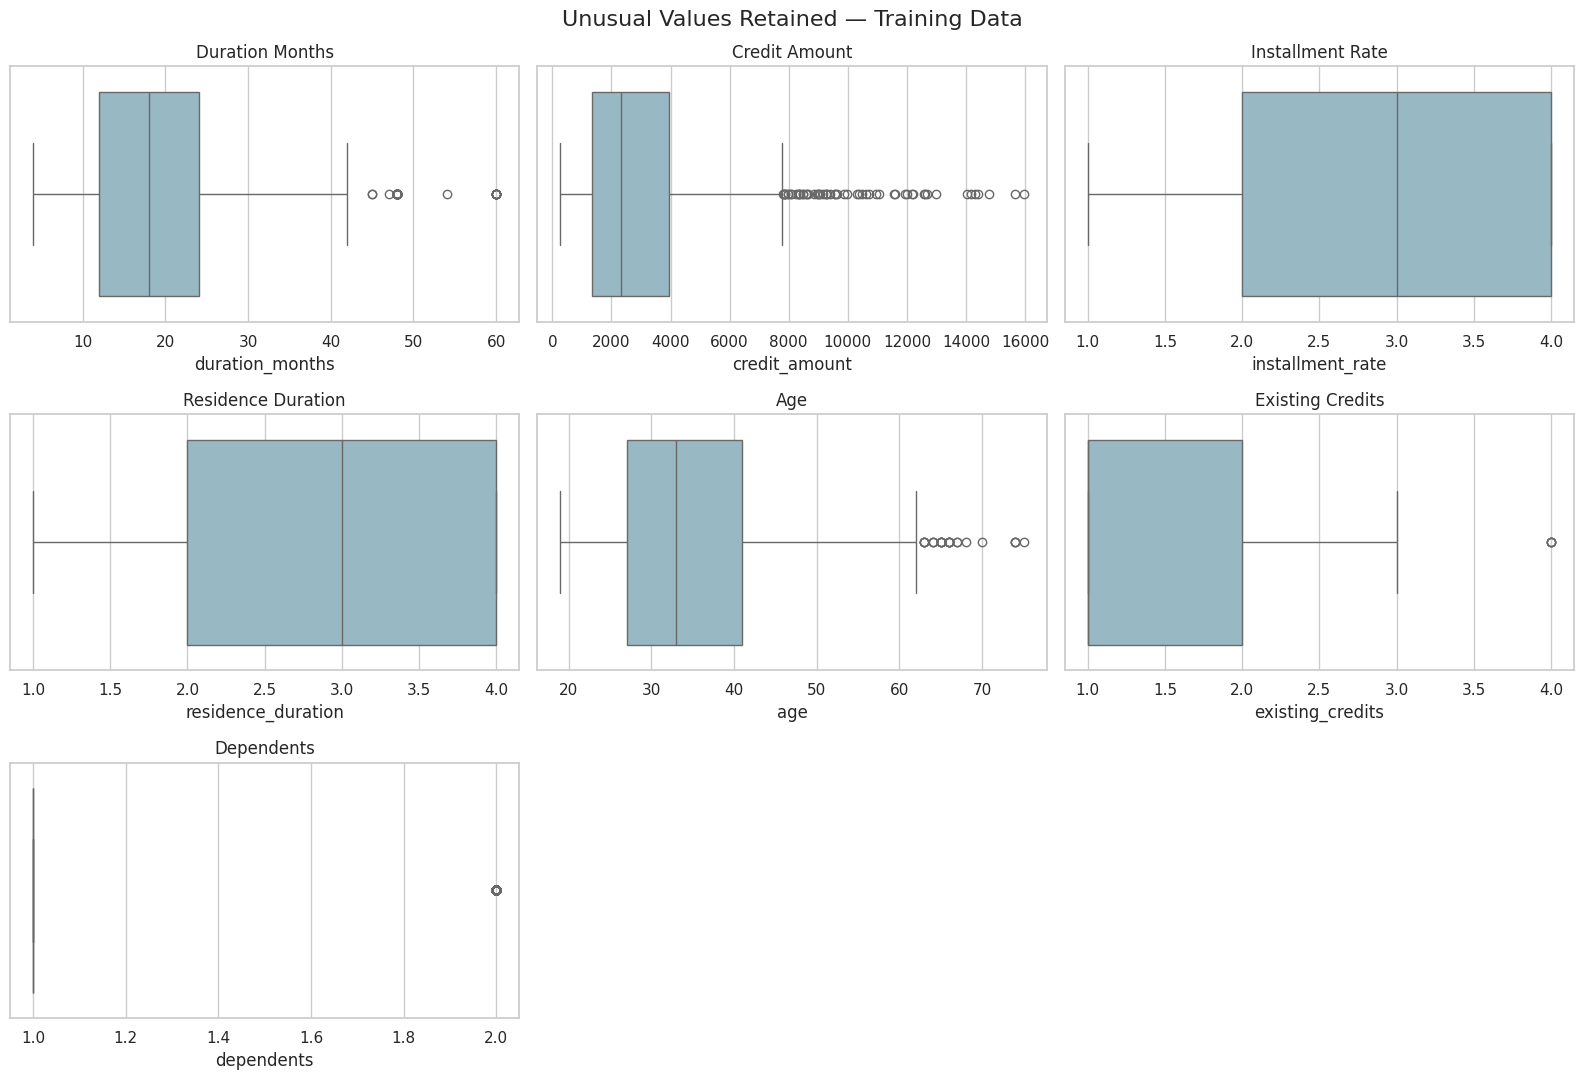

No rows were removed automatically.


In [ ]:
# ============================================================
# STEP 14: FLAG UNUSUAL NUMERICAL VALUES
# ============================================================

outlier_results = []

for column in numeric_features:
    q1 = eda[column].quantile(0.25)
    q3 = eda[column].quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    iqr_flag = ~eda[column].between(
        lower_fence,
        upper_fence
    )

    outlier_results.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_fence": lower_fence,
        "Upper_fence": upper_fence,
        "Flagged_values": int(iqr_flag.sum())
    })

outlier_summary = pd.DataFrame(outlier_results)

save_table(
    outlier_summary,
    "08_outlier_summary_train",
    index=False
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(16, 11)
)

axes = axes.flatten()

for ax, column in zip(axes, numeric_features):
    sns.boxplot(
        data=eda,
        x=column,
        ax=ax,
        color="#91BDCB"
    )

    ax.set_title(
        column.replace("_", " ").title()
    )

for ax in axes[len(numeric_features):]:
    ax.axis("off")

fig.suptitle(
    "Unusual Values Retained — Training Data",
    fontsize=16
)

finish_plot("02_numerical_boxplots_train")

print("No rows were removed automatically.")

,Count,Percent
risk_label,,
Good risk,560,70.000
Bad risk,240,30.000


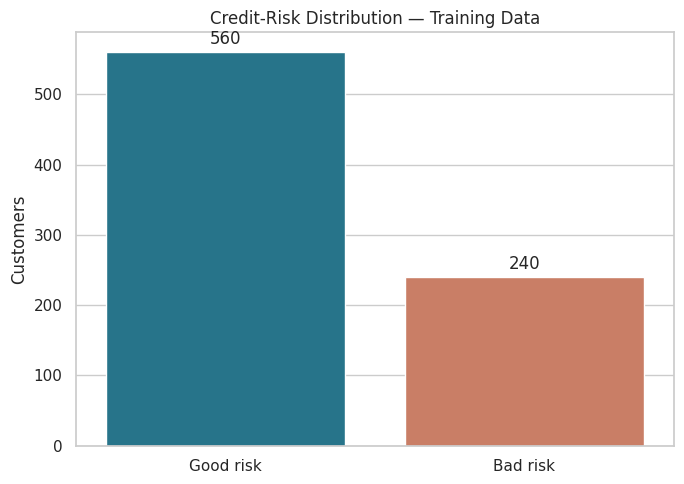

In [ ]:
# ============================================================
# STEP 15: TARGET DISTRIBUTION
# ============================================================

target_counts = (
    eda["risk_label"]
    .value_counts()
    .reindex(["Good risk", "Bad risk"])
)

target_table = pd.DataFrame({
    "Count": target_counts,
    "Percent": target_counts / len(eda) * 100
})

save_table(
    target_table,
    "09_target_distribution_train"
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=target_table.index,
    y=target_table["Count"],
    hue=target_table.index,
    palette={
        "Good risk": "#167D9A",
        "Bad risk": "#DA7655"
    },
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Credit-Risk Distribution — Training Data")
plt.xlabel("")
plt.ylabel("Customers")

finish_plot("03_target_distribution_train")

duration_months               credit_amount                      \
                      mean median    std          mean    median       std   
risk_label                                                                   
Bad risk            24.492 24.000 12.641     3,755.988 2,467.500 3,304.374   
Good risk           19.175 18.000 11.081     2,946.850 2,242.500 2,313.348   

           installment_rate              residence_duration               \
                       mean median   std               mean median   std   
risk_label                                                                 
Bad risk              3.079  4.000 1.093              2.833  3.000 1.119   
Good risk             2.882  3.000 1.134              2.829  3.000 1.109   

              age               existing_credits              dependents  \
             mean median    std             mean median   std       mean   
risk_label                                                                 
Bad risk   34.350 31.000 11.315            1.367  1.000 0.548      1.167   
Good risk  35.741 34.000 10.911            1.425  1.000 0.575      1.157   

                         
           median   std  
risk_label               
Bad risk    1.000 0.373  
Good risk   1.000 0.364

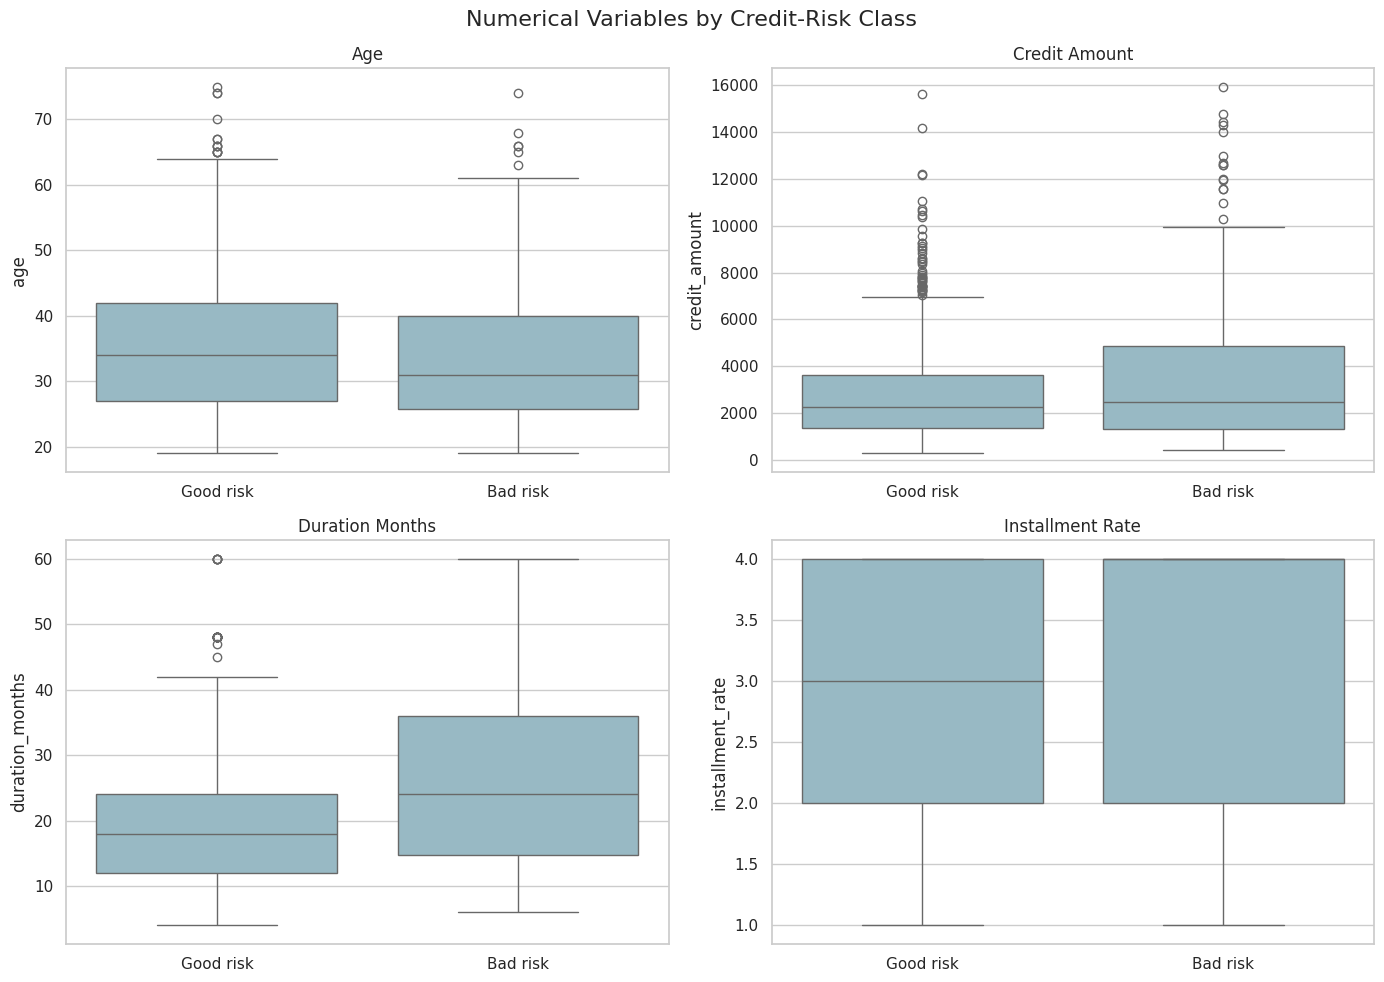

In [ ]:
# ============================================================
# STEP 16: NUMERICAL VARIABLES BY CREDIT RISK
# ============================================================

numerical_by_risk = (
    eda.groupby("risk_label")[numeric_features]
       .agg(["mean", "median", "std"])
)

save_table(
    numerical_by_risk,
    "10_numerical_by_risk_train"
)

selected_numeric = [
    "age",
    "credit_amount",
    "duration_months",
    "installment_rate"
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

for ax, column in zip(axes.flatten(), selected_numeric):
    sns.boxplot(
        data=eda,
        x="risk_label",
        y=column,
        order=["Good risk", "Bad risk"],
        ax=ax,
        color="#91BDCB"
    )

    ax.set_xlabel("")
    ax.set_title(
        column.replace("_", " ").title()
    )

fig.suptitle(
    "Numerical Variables by Credit-Risk Class",
    fontsize=16
)

finish_plot("04_numerical_variables_by_risk")

,Variable,Category,Count,Percent
0,checking_status,no_checking_account,316,39.500
1,checking_status,less_than_0_DM,219,27.375
2,checking_status,0_to_less_than_200_DM,214,26.750
3,checking_status,at_least_200_DM,51,6.375
4,credit_history,existing_credits_paid_duly,416,52.000
5,credit_history,critical_account_or_other_credits,240,30.000
6,credit_history,payment_delay_in_past,72,9.000
7,credit_history,all_bank_credits_paid,41,5.125
8,credit_history,no_credit_or_all_paid,31,3.875
9,purpose,radio_television,215,26.875


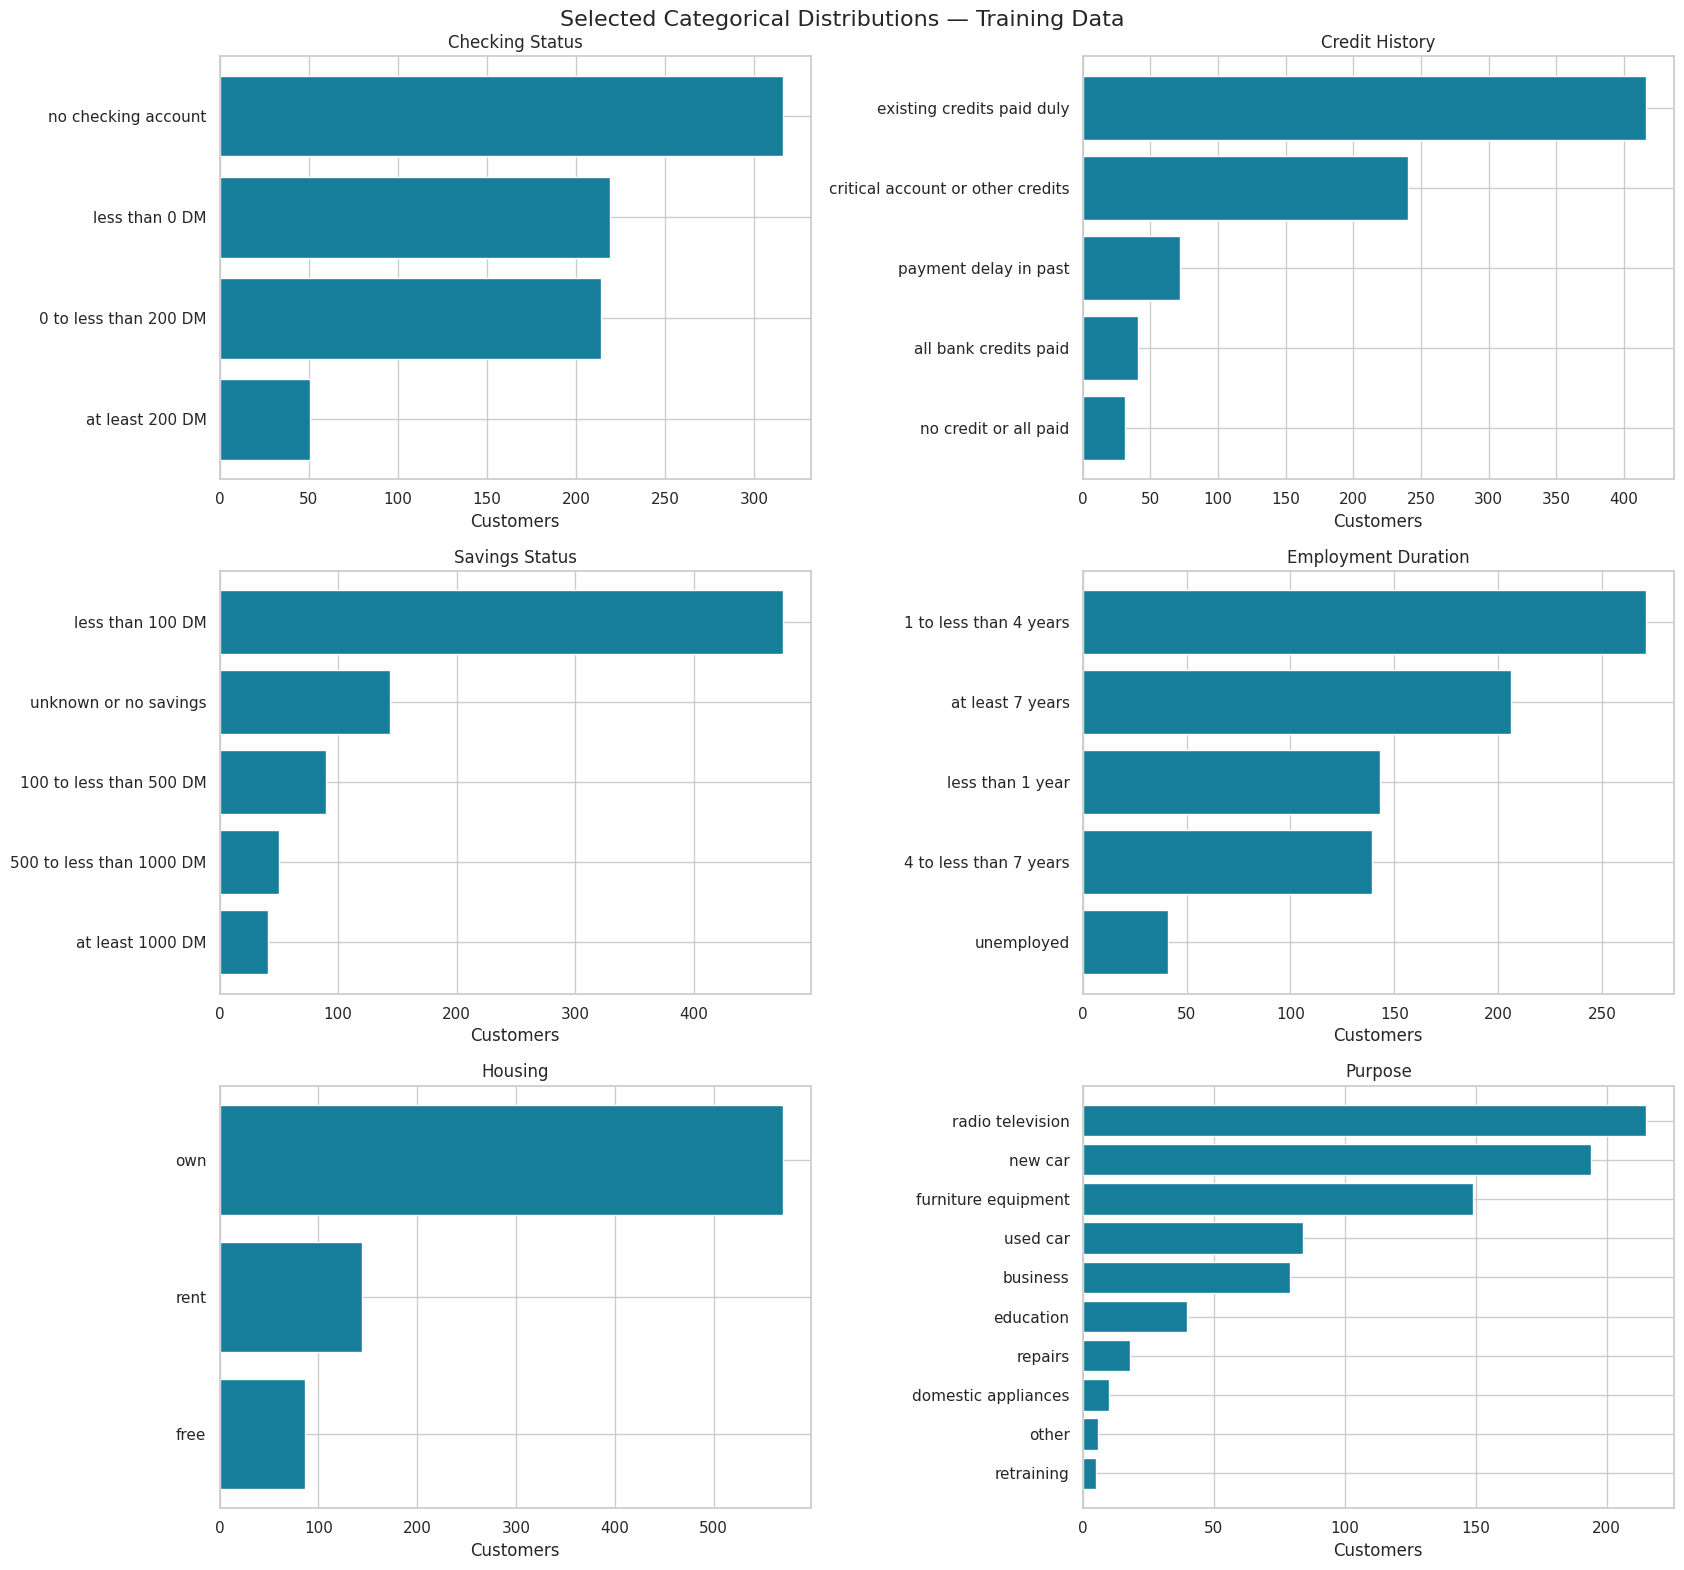

In [ ]:
# ============================================================
# STEP 17: CATEGORICAL FREQUENCIES
# ============================================================

category_frequency_tables = []

for column in categorical_features:
    counts = eda[column].value_counts(dropna=False)

    result = pd.DataFrame({
        "Variable": column,
        "Category": counts.index.astype(str),
        "Count": counts.values,
        "Percent": counts.values / len(eda) * 100
    })

    category_frequency_tables.append(result)

category_frequencies = pd.concat(
    category_frequency_tables,
    ignore_index=True
)

save_table(
    category_frequencies,
    "11_categorical_frequencies_train",
    index=False
)

selected_categories = [
    "checking_status",
    "credit_history",
    "savings_status",
    "employment_duration",
    "housing",
    "purpose"
]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(17, 16)
)

for ax, column in zip(axes.flatten(), selected_categories):
    counts = eda[column].value_counts().sort_values()

    ax.barh(
        counts.index.str.replace("_", " "),
        counts.values,
        color="#167D9A"
    )

    ax.set_title(
        column.replace("_", " ").title()
    )

    ax.set_xlabel("Customers")

fig.suptitle(
    "Selected Categorical Distributions — Training Data",
    fontsize=16
)

finish_plot("05_selected_categorical_distributions")

,Variable,Category,Customers,Bad_risk_cases,Bad_risk_rate,Bad_risk_percent
0,checking_status,0_to_less_than_200_DM,214,84,0.393,39.300
1,checking_status,at_least_200_DM,51,13,0.255,25.500
2,checking_status,less_than_0_DM,219,105,0.479,47.900
3,checking_status,no_checking_account,316,38,0.120,12.000
4,credit_history,all_bank_credits_paid,41,22,0.537,53.700
5,credit_history,critical_account_or_other_credits,240,42,0.175,17.500
6,credit_history,existing_credits_paid_duly,416,134,0.322,32.200
7,credit_history,no_credit_or_all_paid,31,19,0.613,61.300
8,credit_history,payment_delay_in_past,72,23,0.319,31.900
9,purpose,business,79,26,0.329,32.900


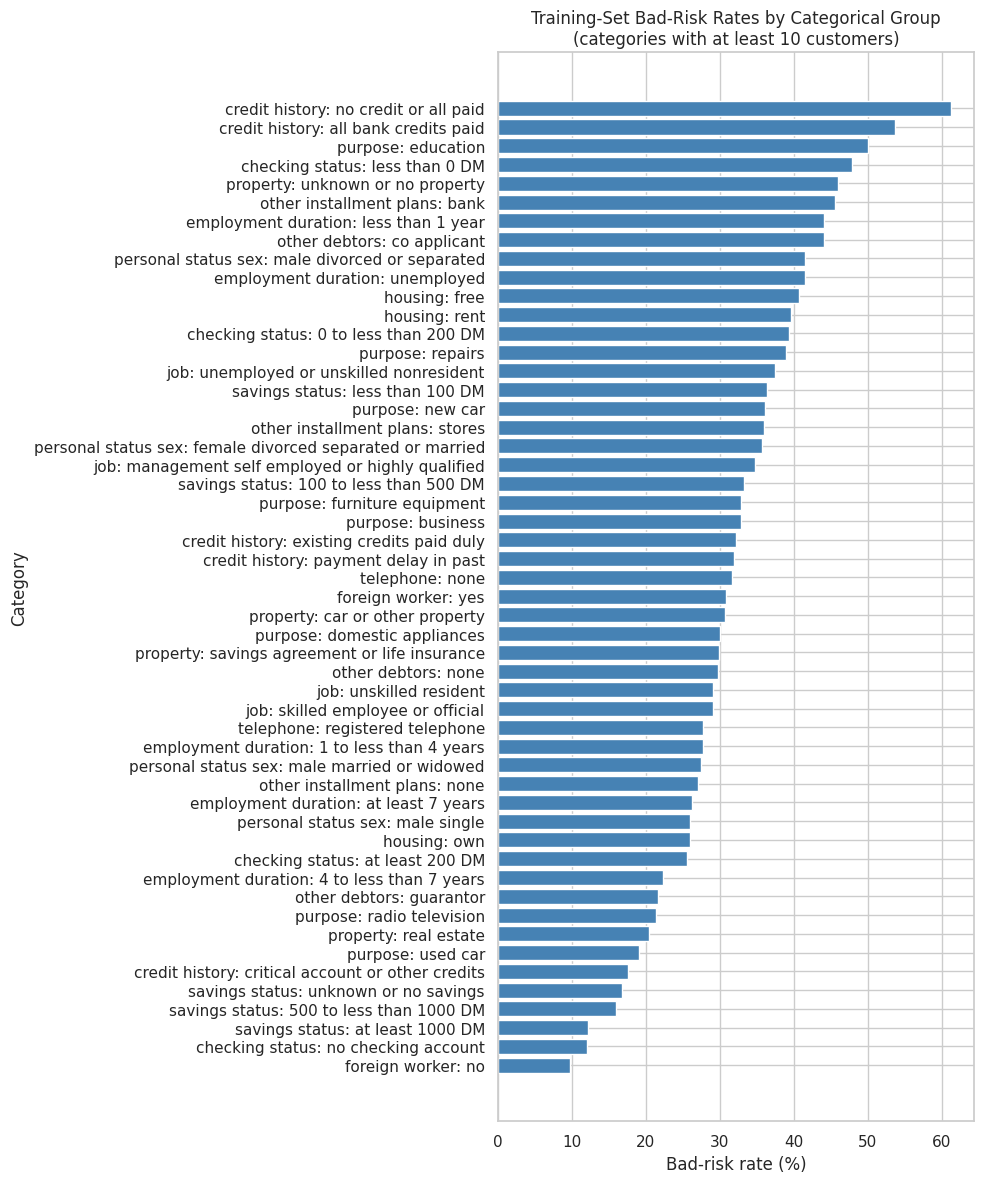

In [ ]:
# ============================================================
# STEP 18: CATEGORICAL BAD-RISK RATES
# ============================================================

category_risk_tables = []

for column in categorical_features:

    result = (
        eda.groupby(column, observed=True)["bad_risk"]
        .agg(
            Customers="size",
            Bad_risk_cases="sum",
            Bad_risk_rate="mean"
        )
        .reset_index()
        .rename(columns={column: "Category"})
    )

    result.insert(0, "Variable", column)

    result["Bad_risk_percent"] = (
        result["Bad_risk_rate"] * 100
    ).round(1)

    category_risk_tables.append(result)

category_risk_summary = pd.concat(
    category_risk_tables,
    ignore_index=True
)

display(category_risk_summary)

# Plot the categories with enough observations to interpret.
plot_data = category_risk_summary[
    category_risk_summary["Customers"] >= 10
].copy()

plot_data = plot_data.sort_values(
    "Bad_risk_percent",
    ascending=True
)

plt.figure(figsize=(10, 12))

labels = (
    plot_data["Variable"]
    + ": "
    + plot_data["Category"].astype(str)
).str.replace("_", " ", regex=False)

plt.barh(
    labels,
    plot_data["Bad_risk_percent"],
    color="steelblue"
)

plt.xlabel("Bad-risk rate (%)")
plt.ylabel("Category")
plt.title(
    "Training-Set Bad-Risk Rates by Categorical Group\n"
    "(categories with at least 10 customers)"
)

plt.tight_layout()
plt.show()

,duration_months,credit_amount,installment_rate,residence_duration,age,existing_credits,dependents,bad_risk
duration_months,1.000,0.638,0.098,0.020,-0.040,0.009,-0.006,0.206
credit_amount,0.638,1.000,-0.241,0.033,0.029,0.049,0.040,0.139
installment_rate,0.098,-0.241,1.000,0.072,0.084,0.028,-0.077,0.080
residence_duration,0.020,0.033,0.072,1.000,0.238,0.090,0.036,0.002
age,-0.040,0.029,0.084,0.238,1.000,0.148,0.113,-0.058
existing_credits,0.009,0.049,0.028,0.090,0.148,1.000,0.107,-0.047
dependents,-0.006,0.040,-0.077,0.036,0.113,0.107,1.000,0.012
bad_risk,0.206,0.139,0.080,0.002,-0.058,-0.047,0.012,1.000


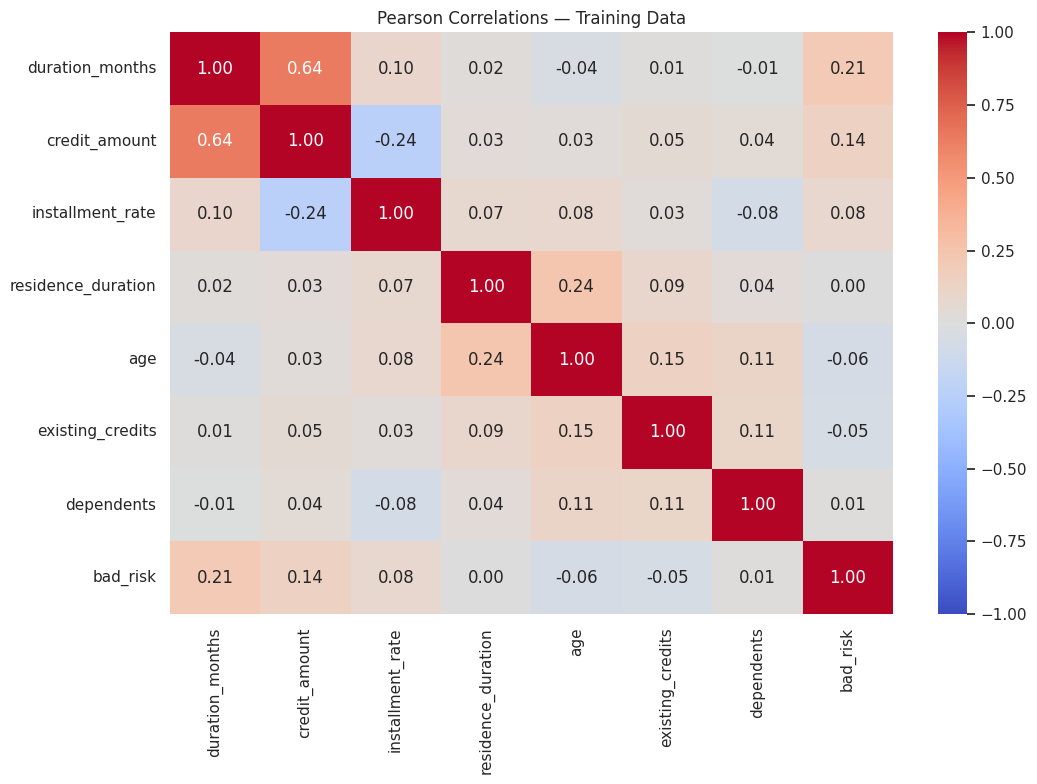

In [ ]:
# ============================================================
# STEP 19: NUMERICAL CORRELATION ANALYSIS
# ============================================================

correlation_matrix = eda[
    numeric_features + ["bad_risk"]
].corr()

save_table(
    correlation_matrix,
    "13_numerical_correlations_train"
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    "Pearson Correlations — Training Data"
)

finish_plot("07_numerical_correlation_heatmap")

In [ ]:
# ============================================================
# STEP 20: CATEGORICAL ASSOCIATION CHECKS
# ============================================================

association_results = []

for column in categorical_features:
    contingency_table = pd.crosstab(
        eda[column],
        eda["bad_risk"]
    )

    chi2, p_value, degrees_freedom, expected = (
        chi2_contingency(
            contingency_table,
            correction=False
        )
    )

    expected_under_5_percent = (
        (expected < 5).mean() * 100
    )

    approximation_acceptable = (
        (expected >= 1).all()
        and expected_under_5_percent <= 20
    )

    association_results.append({
        "Variable": column,
        "Chi_square": chi2,
        "P_value": p_value,
        "Degrees_freedom": degrees_freedom,
        "Minimum_expected_count": expected.min(),
        "Expected_under_5_percent":
            expected_under_5_percent,
        "Approximation_acceptable":
            approximation_acceptable
    })

association_table = (
    pd.DataFrame(association_results)
      .sort_values("P_value")
      .reset_index(drop=True)
)

# Holm multiple-testing correction.
number_of_tests = len(association_table)

raw_adjusted = (
    association_table["P_value"].to_numpy()
    * (number_of_tests - np.arange(number_of_tests))
)

association_table["Holm_adjusted_p"] = np.minimum(
    1,
    np.maximum.accumulate(raw_adjusted)
)

association_table["Interpretation"] = np.where(
    ~association_table["Approximation_acceptable"],
    "Sparse cells: interpret cautiously",
    np.where(
        association_table["Holm_adjusted_p"] < 0.05,
        "Evidence of association",
        "No clear evidence after adjustment"
    )
)

save_table(
    association_table,
    "14_categorical_association_tests_train",
    index=False
)

,Variable,Chi_square,P_value,Degrees_freedom,Minimum_expected_count,Expected_under_5_percent,Approximation_acceptable,Holm_adjusted_p,Interpretation
0,checking_status,91.418,0.000,3,15.300,0.000,True,0.000,Evidence of association
1,credit_history,44.337,0.000,4,9.300,0.000,True,0.000,Evidence of association
2,savings_status,32.848,0.000,4,12.300,0.000,True,0.000,Evidence of association
3,property,24.904,0.000,3,37.200,0.000,True,0.000,Evidence of association
4,employment_duration,22.045,0.000,4,12.300,0.000,True,0.002,Evidence of association
5,other_installment_plans,16.366,0.000,2,11.700,0.000,True,0.002,Evidence of association
6,housing,15.404,0.000,2,25.800,0.000,True,0.003,Evidence of association
7,purpose,25.272,0.003,9,1.500,25.000,False,0.016,Sparse cells: interpret cautiously
8,foreign_worker,6.343,0.012,1,9.300,0.000,True,0.059,No clear evidence after adjustment
9,personal_status_sex,9.915,0.019,3,12.300,0.000,True,0.077,No clear evidence after adjustment


,Customers,Bad_risk_cases,Bad_risk_rate,Bad_risk_percent
sex_audit,,,,
female,249,89,0.357,35.743
male,551,151,0.274,27.405


,Customers,Bad_risk_cases,Bad_risk_rate,Bad_risk_percent
age_group_audit,,,,
under_25,110,42,0.382,38.182
25_to_44,537,156,0.291,29.050
45_and_over,153,42,0.275,27.451


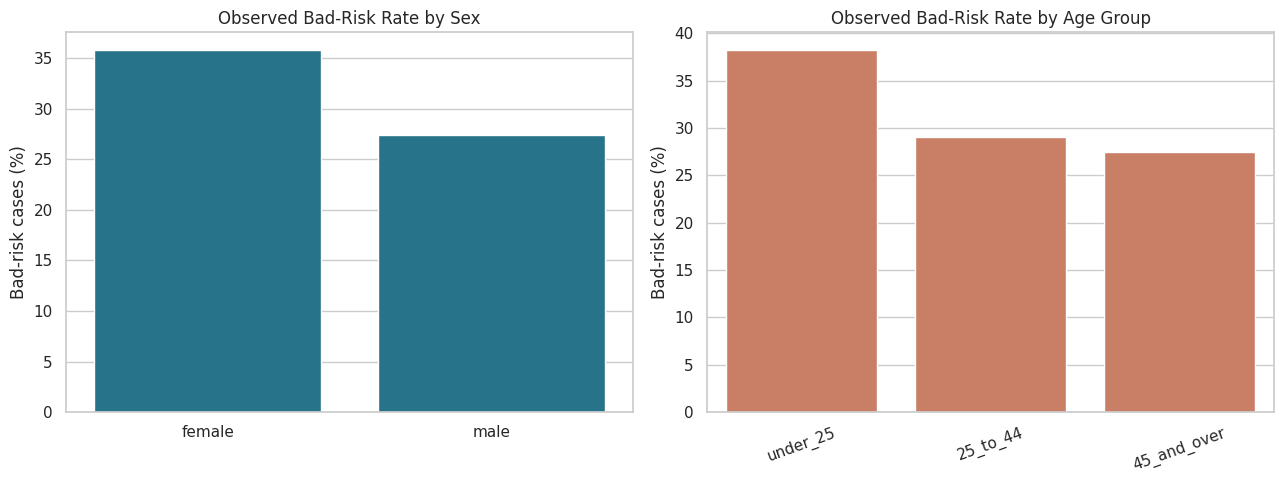

These results describe historical outcome differences. Approval-rate fairness can only be calculated after the model and decision threshold are created.


In [ ]:
# ============================================================
# STEP 21: DESCRIPTIVE PROTECTED-GROUP ANALYSIS
# ============================================================

sex_descriptive = (
    eda.groupby("sex_audit", observed=True)["bad_risk"]
       .agg(
           Customers="size",
           Bad_risk_cases="sum",
           Bad_risk_rate="mean"
       )
)

sex_descriptive["Bad_risk_percent"] = (
    sex_descriptive["Bad_risk_rate"] * 100
)

age_descriptive = (
    eda.groupby("age_group_audit", observed=True)["bad_risk"]
       .agg(
           Customers="size",
           Bad_risk_cases="sum",
           Bad_risk_rate="mean"
       )
)

age_descriptive["Bad_risk_percent"] = (
    age_descriptive["Bad_risk_rate"] * 100
)

save_table(
    sex_descriptive,
    "15_descriptive_risk_by_sex_train"
)

save_table(
    age_descriptive,
    "16_descriptive_risk_by_age_group_train"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

sns.barplot(
    data=sex_descriptive.reset_index(),
    x="sex_audit",
    y="Bad_risk_percent",
    ax=axes[0],
    color="#167D9A"
)

axes[0].set_title("Observed Bad-Risk Rate by Sex")
axes[0].set_xlabel("")
axes[0].set_ylabel("Bad-risk cases (%)")

sns.barplot(
    data=age_descriptive.reset_index(),
    x="age_group_audit",
    y="Bad_risk_percent",
    ax=axes[1],
    color="#DA7655"
)

axes[1].set_title("Observed Bad-Risk Rate by Age Group")
axes[1].set_xlabel("")
axes[1].set_ylabel("Bad-risk cases (%)")
axes[1].tick_params(axis="x", rotation=20)

finish_plot("08_descriptive_protected_group_analysis")

print(
    "These results describe historical outcome differences. "
    "Approval-rate fairness can only be calculated after the "
    "model and decision threshold are created."
)

,Original_skew,Log1p_skew
credit_amount,1.826,0.095
duration_months,1.047,-0.065


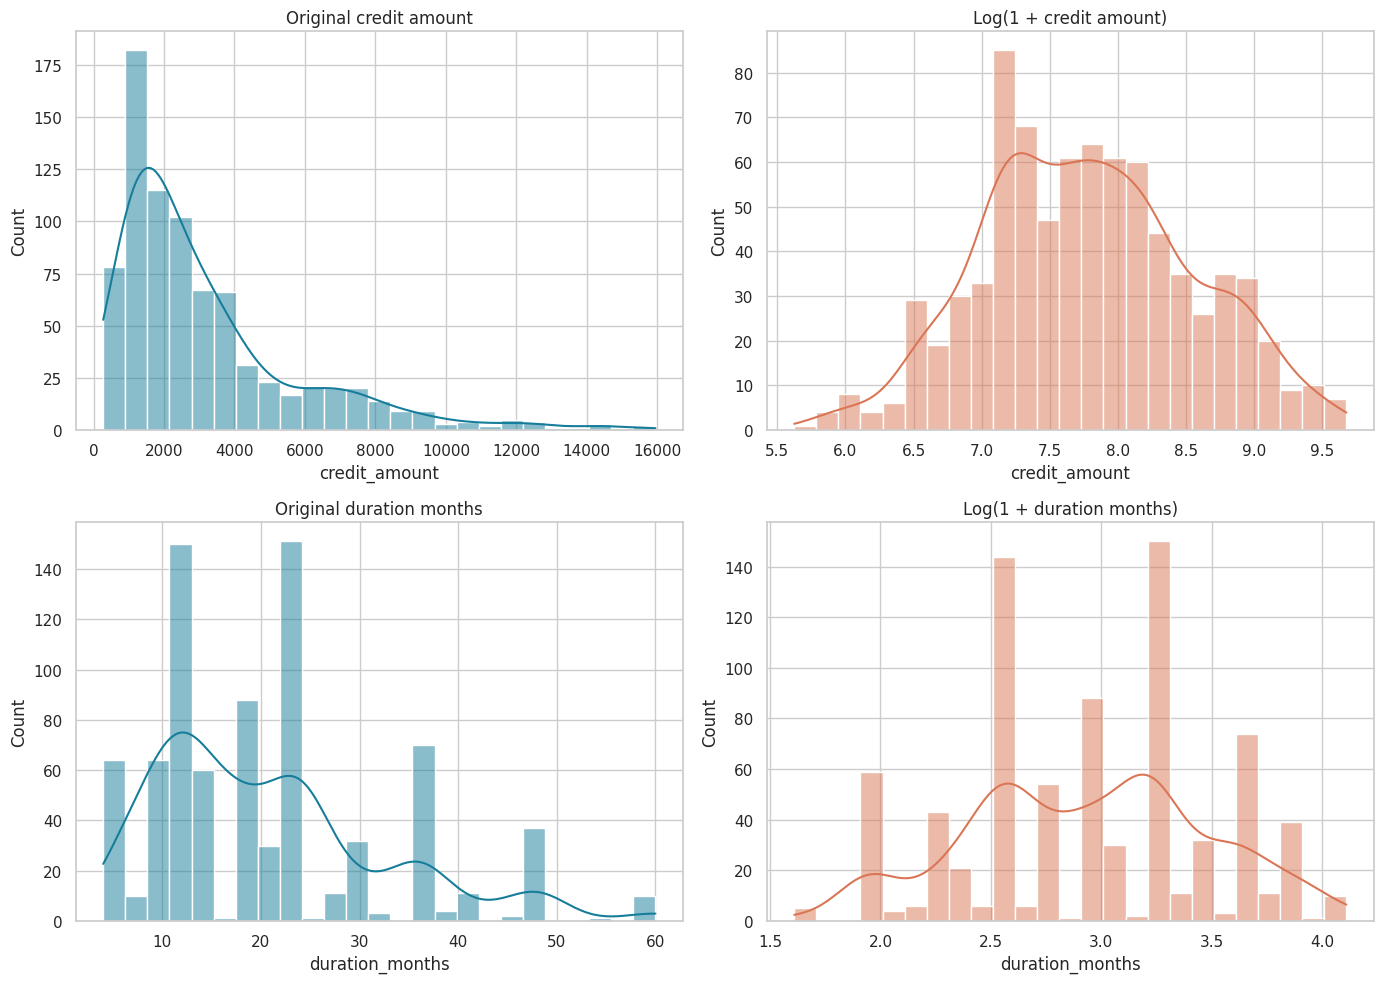

No transformation has been permanently applied. Member 2 will decide transformations inside the training pipeline.


In [ ]:
# ============================================================
# STEP 22: TRANSFORMATION CHECK FOR SKEWED VARIABLES
# ============================================================

transformation_variables = [
    "credit_amount",
    "duration_months"
]

transformation_summary = pd.DataFrame({
    "Original_skew":
        eda[transformation_variables].skew(),

    "Log1p_skew":
        np.log1p(
            eda[transformation_variables]
        ).skew()
})

save_table(
    transformation_summary,
    "17_transformation_comparison_train"
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

for row, column in enumerate(transformation_variables):
    sns.histplot(
        eda[column],
        bins=25,
        kde=True,
        ax=axes[row, 0],
        color="#167D9A"
    )

    axes[row, 0].set_title(
        f"Original {column.replace('_', ' ')}"
    )

    sns.histplot(
        np.log1p(eda[column]),
        bins=25,
        kde=True,
        ax=axes[row, 1],
        color="#DA7655"
    )

    axes[row, 1].set_title(
        f"Log(1 + {column.replace('_', ' ')})"
    )

finish_plot("09_transformation_comparison")

print(
    "No transformation has been permanently applied. "
    "Member 2 will decide transformations inside the "
    "training pipeline."
)

In [ ]:
# ============================================================
# STEP 23: DOCUMENT MODELLING AND AUDIT CONTRACTS
# ============================================================

target_columns = [
    "credit_class",
    "bad_risk",
    "risk_label"
]

identifier_columns = [
    "customer_id"
]

audit_columns = [
    "sex_audit",
    "age_group_audit",
    "personal_status_group"
]

administrative_columns = [
    "split"
]

protected_source_columns = [
    "personal_status_sex"
]

model_contract = pd.DataFrame([
    {
        "Column_group": "Target",
        "Columns": ", ".join(target_columns),
        "Rule": "Never include in predictors"
    },
    {
        "Column_group": "Identifier",
        "Columns": ", ".join(identifier_columns),
        "Rule": "Tracking only; never include in predictors"
    },
    {
        "Column_group": "Audit",
        "Columns": ", ".join(audit_columns),
        "Rule": "Fairness evaluation only"
    },
    {
        "Column_group": "Administrative",
        "Columns": ", ".join(administrative_columns),
        "Rule": "Controls shared data split"
    },
    {
        "Column_group": "Protected source",
        "Columns": ", ".join(protected_source_columns),
        "Rule": "Exclude from primary model; retain for audit traceability"
    }
])

save_table(
    model_contract,
    "18_model_contract",
    index=False
)

,Column_group,Columns,Rule
0,Target,"credit_class, bad_risk, risk_label",Never include in predictors
1,Identifier,customer_id,Tracking only; never include in predictors
2,Audit,"sex_audit, age_group_audit, personal_status_group",Fairness evaluation only
3,Administrative,split,Controls shared data split
4,Protected source,personal_status_sex,Exclude from primary model; retain for audit t...


In [ ]:
# ============================================================
# STEP 24: EXPORT ONE FINAL UCI-DESCRIPTION CSV
# ============================================================

final_export = df.copy()

# A. Convert categorical codes into official UCI descriptions safely
for column, description_mapping in (
    uci_official_descriptions.items()
):

    if column == "personal_status_sex":
        continue

    code_column = f"{column}_code"

    assert code_column in final_export.columns, (
        f"Missing original-code column: {code_column}. "
        "Rerun Steps 5–8."
    )

    official_description = (
        final_export[code_column]
        .map(description_mapping)
    )

    assert official_description.notna().all(), (
        f"Missing official UCI description for {column}"
    )

    final_export[column] = official_description

# B. Split UCI Attribute 9 into Sex and Personal status
sex_export_mapping = {
    "A91": "male", "A92": "female", "A93": "male",
    "A94": "male", "A95": "female"
}

personal_status_export_mapping = {
    "A91": "divorced/separated",
    "A92": "divorced/separated/married",
    "A93": "single",
    "A94": "married/widowed",
    "A95": "single"
}

attribute_9_code = final_export["personal_status_sex_code"]
final_export["sex"] = attribute_9_code.map(sex_export_mapping)
final_export["personal_status"] = attribute_9_code.map(personal_status_export_mapping)

assert final_export["sex"].notna().all()
assert final_export["personal_status"].notna().all()

# C. Make derived audit values readable
final_export["age_group_audit"] = (
    final_export["age_group_audit"]
    .astype("string")
    .replace({
        "under_25": "under 25",
        "25_to_44": "25 to 44",
        "45_and_over": "45 and over"
    })
)

# D. Drop temporary code helper columns
columns_to_remove = ["personal_status_sex", "sex_audit", "personal_status_group"]
code_columns = [col for col in final_export.columns if col.endswith("_code")]
final_export = final_export.drop(columns=columns_to_remove + code_columns)

# E. Rename columns for exported dataset
export_column_names = {
    "customer_id": "Customer ID",
    "checking_status": "Status of existing checking account",
    "duration_months": "Duration in month",
    "credit_history": "Credit history",
    "purpose": "Purpose",
    "credit_amount": "Credit amount",
    "savings_status": "Savings account/bonds",
    "employment_duration": "Present employment since",
    "installment_rate": "Installment rate in percentage of disposable income",
    "sex": "Sex",
    "personal_status": "Personal status",
    "other_debtors": "Other debtors / guarantors",
    "residence_duration": "Present residence since",
    "property": "Property",
    "age": "Age in years",
    "other_installment_plans": "Other installment plans",
    "housing": "Housing",
    "existing_credits": "Number of existing credits at this bank",
    "job": "Job",
    "dependents": "Number of people liable to provide maintenance for",
    "telephone": "Telephone",
    "foreign_worker": "Foreign worker",
    "credit_class": "Original credit class",
    "bad_risk": "Bad risk",
    "risk_label": "Risk label",
    "age_group_audit": "Age group",
    "split": "Split"
}

final_export = final_export.rename(columns=export_column_names)

# F. Reorder columns cleanly
final_column_order = [
    "Customer ID",
    "Status of existing checking account",
    "Duration in month",
    "Credit history",
    "Purpose",
    "Credit amount",
    "Savings account/bonds",
    "Present employment since",
    "Installment rate in percentage of disposable income",
    "Sex",
    "Personal status",
    "Other debtors / guarantors",
    "Present residence since",
    "Property",
    "Age in years",
    "Other installment plans",
    "Housing",
    "Number of existing credits at this bank",
    "Job",
    "Number of people liable to provide maintenance for",
    "Telephone",
    "Foreign worker",
    "Original credit class",
    "Bad risk",
    "Risk label",
    "Age group",
    "Split"
]

final_export = final_export[final_column_order].copy()

# G. Save final exported CSV
FINAL_CSV = Path("/content/German_Credit_Final_UCI_Descriptions.csv")
final_export.to_csv(FINAL_CSV,index=False)

print("Final dataset created and exported successfully without mapping errors.")
display(final_export.head())
files.download(str(FINAL_CSV))

Final dataset created and exported successfully without mapping errors.


,Customer ID,Status of existing checking account,Duration in month,Credit history,Purpose,Credit amount,Savings account/bonds,Present employment since,Installment rate in percentage of disposable income,Sex,Personal status,Other debtors / guarantors,Present residence since,Property,Age in years,Other installment plans,Housing,Number of existing credits at this bank,Job,Number of people liable to provide maintenance for,Telephone,Foreign worker,Original credit class,Bad risk,Risk label,Age group,Split
0,1,x < 0 DM,6,critical account / other credits existing (not...,radio/television,1169,unknown / no savings account,x >= 7 years,4,male,single,none,4,real estate,67,none,own,2,skilled employee / official,1,"yes, registered under the customer's name",yes,1,0,Good risk,45 and over,train
1,2,0 DM <= x < 200 DM,48,existing credits paid back duly till now,radio/television,5951,x < 100 DM,1 year <= x < 4 years,2,female,divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee / official,1,none,yes,2,1,Bad risk,under 25,test
2,3,no checking account,12,critical account / other credits existing (not...,education,2096,x < 100 DM,4 years <= x < 7 years,2,male,single,none,3,real estate,49,none,own,1,unskilled - resident,2,none,yes,1,0,Good risk,45 and over,test
3,4,x < 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,x < 100 DM,4 years <= x < 7 years,2,male,single,guarantor,4,building society savings agreement / life insu...,45,none,for free,1,skilled employee / official,2,none,yes,1,0,Good risk,45 and over,train
4,5,x < 0 DM,24,delay in paying off in the past,car (new),4870,x < 100 DM,1 year <= x < 4 years,3,male,single,none,4,unknown / no property,53,none,for free,2,skilled employee / official,2,none,yes,2,1,Bad risk,45 and over,train


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# STEP 25: FINAL CSV INTEGRITY CHECKS
# ============================================================

reloaded = pd.read_csv(
    "/content/German_Credit_Final_UCI_Descriptions.csv"
)

# ------------------------------------------------------------
# A. Confirm customer records and target.
# ------------------------------------------------------------

assert len(reloaded) == 1000

assert reloaded["Customer ID"].is_unique

assert reloaded["Bad risk"].isin(
    [0, 1]
).all()

# ------------------------------------------------------------
# B. Confirm shared train-test split.
# ------------------------------------------------------------

assert reloaded["Split"].isin(
    ["train", "test"]
).all()

assert (
    reloaded["Split"] == "train"
).sum() == 800

assert (
    reloaded["Split"] == "test"
).sum() == 200

# ------------------------------------------------------------
# C. Confirm official Purpose descriptions.
# ------------------------------------------------------------

purpose_values = set(
    reloaded["Purpose"]
)

assert "car (new)" in purpose_values
assert "car (used)" in purpose_values
assert "furniture/equipment" in purpose_values
assert "radio/television" in purpose_values
assert "others" in purpose_values

assert "new_car" not in purpose_values
assert "used_car" not in purpose_values
assert "radio_television" not in purpose_values
assert "car (used)0" not in purpose_values

# ------------------------------------------------------------
# D. Confirm x-based boundary descriptions.
# ------------------------------------------------------------

checking_values = set(
    reloaded[
        "Status of existing checking account"
    ]
)

assert "x < 0 DM" in checking_values
assert "0 DM <= x < 200 DM" in checking_values

savings_values = set(
    reloaded["Savings account/bonds"]
)

assert "x < 100 DM" in savings_values
assert "100 DM <= x < 500 DM" in savings_values

employment_values = set(
    reloaded["Present employment since"]
)

assert "x < 1 year" in employment_values
assert "1 year <= x < 4 years" in employment_values

# ------------------------------------------------------------
# E. Confirm Attribute 9 was split correctly.
# ------------------------------------------------------------

assert "Sex" in reloaded.columns
assert "Personal status" in reloaded.columns

assert (
    "Personal status and sex"
    not in reloaded.columns
)

assert set(
    reloaded["Sex"]
).issubset(
    {"male", "female"}
)

expected_personal_statuses = {
    "divorced/separated",
    "divorced/separated/married",
    "single",
    "married/widowed"
}

assert set(
    reloaded["Personal status"]
).issubset(
    expected_personal_statuses
)

assert reloaded["Sex"].notna().all()

assert (
    reloaded["Personal status"]
    .notna()
    .all()
)

# ------------------------------------------------------------
# F. Confirm exported values contain no machine labels.
# ------------------------------------------------------------

assert "male_single" not in set(
    reloaded["Personal status"]
)

assert (
    "female_divorced_separated_or_married"
    not in set(reloaded["Personal status"])
)

assert not any(
    column.endswith("_code")
    for column in reloaded.columns
)

assert not any(
    column.endswith("_uci_description")
    for column in reloaded.columns
)

# ------------------------------------------------------------
# G. Confirm the CSV is stored in Colab.
# ------------------------------------------------------------

assert FINAL_CSV.exists()

print("PASS: The final CSV contains 1,000 customers.")
print("PASS: UCI category codes were replaced by descriptions.")
print("PASS: UCI ellipses were presented as x.")
print("PASS: Attribute 9 was split into Sex and Personal status.")
print("PASS: No machine-friendly underscore labels remain.")
print("PASS: The shared 800/200 split is included.")
print("PASS: The file is stored in the Colab Files panel.")
print("The final dataset is ready for the group.")

PASS: The final CSV contains 1,000 customers.
PASS: UCI category codes were replaced by descriptions.
PASS: UCI ellipses were presented as x.
PASS: Attribute 9 was split into Sex and Personal status.
PASS: No machine-friendly underscore labels remain.
PASS: The shared 800/200 split is included.
PASS: The file is stored in the Colab Files panel.
The final dataset is ready for the group.


,Model,Accuracy,Balanced_accuracy,Precision_bad_risk,Recall_bad_risk,F1_bad_risk,ROC_AUC,Average_precision,False_approval_bad_customer,False_rejection_good_customer,UCI_total_cost
0,Majority-class baseline,0.700,0.500,0.000,0.000,0.000,0.500,0.300,60,0,300


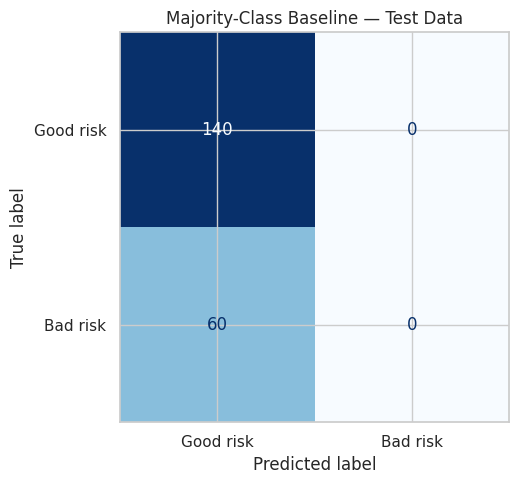

Baseline model completed.
This benchmark shows the performance obtained without learning customer-level patterns.


In [ ]:
# ============================================================
# STEP 25A: CREATE SIMPLE MAJORITY-CLASS BASELINE
# ============================================================

# ------------------------------------------------------------
# A. Prepare a minimal input.
#
# DummyClassifier does not use the predictor values.
# Age is supplied only because sklearn expects an X table.
# ------------------------------------------------------------

X_train_baseline = train_df[
    ["age"]
].copy()

y_train_baseline = train_df[
    "bad_risk"
].copy()

X_test_baseline = test_df[
    ["age"]
].copy()

y_test_baseline = test_df[
    "bad_risk"
].copy()

# ------------------------------------------------------------
# B. Train the baseline.
#
# strategy="prior" predicts according to the most common
# training class. In this dataset, good risk is more common.
# ------------------------------------------------------------

baseline_model = DummyClassifier(
    strategy="prior",
    random_state=SEED
)

baseline_model.fit(
    X_train_baseline,
    y_train_baseline
)

# ------------------------------------------------------------
# C. Generate test predictions and bad-risk probabilities.
# ------------------------------------------------------------

baseline_prediction = baseline_model.predict(
    X_test_baseline
)

baseline_probability = baseline_model.predict_proba(
    X_test_baseline
)[:, 1]

# ------------------------------------------------------------
# D. Calculate baseline performance.
# ------------------------------------------------------------

baseline_confusion = confusion_matrix(
    y_test_baseline,
    baseline_prediction,
    labels=[0, 1]
)

baseline_tn = baseline_confusion[0, 0]
baseline_fp = baseline_confusion[0, 1]
baseline_fn = baseline_confusion[1, 0]
baseline_tp = baseline_confusion[1, 1]

# UCI cost assumptions:
# - Rejecting a good customer costs 1 unit.
# - Approving a bad customer costs 5 units.
baseline_total_cost = (
    baseline_fp * 1
    + baseline_fn * 5
)

baseline_metrics = pd.DataFrame({
    "Model": [
        "Majority-class baseline"
    ],
    "Accuracy": [
        accuracy_score(
            y_test_baseline,
            baseline_prediction
        )
    ],
    "Balanced_accuracy": [
        balanced_accuracy_score(
            y_test_baseline,
            baseline_prediction
        )
    ],
    "Precision_bad_risk": [
        precision_score(
            y_test_baseline,
            baseline_prediction,
            zero_division=0
        )
    ],
    "Recall_bad_risk": [
        recall_score(
            y_test_baseline,
            baseline_prediction,
            zero_division=0
        )
    ],
    "F1_bad_risk": [
        f1_score(
            y_test_baseline,
            baseline_prediction,
            zero_division=0
        )
    ],
    "ROC_AUC": [
        roc_auc_score(
            y_test_baseline,
            baseline_probability
        )
    ],
    "Average_precision": [
        average_precision_score(
            y_test_baseline,
            baseline_probability
        )
    ],
    "False_approval_bad_customer": [
        baseline_fn
    ],
    "False_rejection_good_customer": [
        baseline_fp
    ],
    "UCI_total_cost": [
        baseline_total_cost
    ]
})

display(
    baseline_metrics.round(3)
)

# ------------------------------------------------------------
# E. Plot baseline confusion matrix.
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6, 5)
)

ConfusionMatrixDisplay(
    confusion_matrix=baseline_confusion,
    display_labels=[
        "Good risk",
        "Bad risk"
    ]
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title(
    "Majority-Class Baseline — Test Data"
)

plt.tight_layout()
plt.show()

print("Baseline model completed.")
print(
    "This benchmark shows the performance obtained "
    "without learning customer-level patterns."
)

In [ ]:
# ============================================================
# MEMBER 1 CHECKPOINT
# ============================================================

print("Member 1 data preparation and EDA completed.")

print("\nDataset summary:")
print("Customers:", len(df))
print("Original UCI predictors: 20")
print(
    "Training customers:",
    (df["split"] == "train").sum()
)
print(
    "Test customers:",
    (df["split"] == "test").sum()
)

print("\nOne final CSV is stored in Colab:")
print(FINAL_CSV)

print(
    "\nThe CSV contains official UCI descriptions, "
    "targets, audit variables and the shared split."
)

print(
    "The in-memory df, train_df and test_df remain available "
    "for Member 2 modelling."
)

print("\nBaseline test performance:")
display(
    baseline_metrics.round(3)
)

Member 1 data preparation and EDA completed.

Dataset summary:
Customers: 1000
Original UCI predictors: 20
Training customers: 800
Test customers: 200

One final CSV is stored in Colab:
/content/German_Credit_Final_UCI_Descriptions.csv

The CSV contains official UCI descriptions, targets, audit variables and the shared split.
The in-memory df, train_df and test_df remain available for Member 2 modelling.

Baseline test performance:


,Model,Accuracy,Balanced_accuracy,Precision_bad_risk,Recall_bad_risk,F1_bad_risk,ROC_AUC,Average_precision,False_approval_bad_customer,False_rejection_good_customer,UCI_total_cost
0,Majority-class baseline,0.700,0.500,0.000,0.000,0.000,0.500,0.300,60,0,300


## Yee Ling - Member 2

In [ ]:
# ============================================================
# STEP 26: SETUP AND VERIFY MEMBER 1 HANDOVER
# ============================================================

# All required libraries were already imported in Step 1.

# ------------------------------------------------------------
# A. Create Member 2 output folders.
# ------------------------------------------------------------

MEMBER2_OUTPUT = Path(
    "member2_scorecard_outputs"
)

MEMBER2_FIGURES = (
    MEMBER2_OUTPUT / "figures"
)

MEMBER2_MODELS = (
    MEMBER2_OUTPUT / "models"
)

MEMBER2_DATA = (
    MEMBER2_OUTPUT / "data"
)

for directory in [
    MEMBER2_FIGURES,
    MEMBER2_MODELS,
    MEMBER2_DATA
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# B. Create Member 2 display and plotting functions.
# ------------------------------------------------------------

def save_member2_table(
    data,
    name=None,
    index=True
):
    """
    Display a Member 2 result table.

    Intermediate result tables are not exported as separate
    CSV files to avoid creating unnecessary files.
    """

    display(data)


def finish_member2_plot(name):
    """Save, display and close a Member 2 figure."""

    plt.tight_layout()

    plt.savefig(
        MEMBER2_FIGURES / f"{name}.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# C. Verify Member 1's handover.
# ------------------------------------------------------------

required_variables = [
    "df",
    "train_df",
    "test_df"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

assert not missing_variables, (
    "Run Member 1's cells first. Missing variables: "
    + ", ".join(missing_variables)
)

assert len(df) == 1000
assert len(train_df) == 800
assert len(test_df) == 200

assert set(
    train_df["customer_id"]
).isdisjoint(
    set(test_df["customer_id"])
)

assert (
    len(train_df)
    + len(test_df)
    == len(df)
)

print("Member 1 handover successfully verified.")
print("Full dataset:", df.shape)
print("Training customers:", len(train_df))
print("Test customers:", len(test_df))
print("Member 2 output folders are ready.")

Member 1 handover successfully verified.
Full dataset: (1000, 41)
Training customers: 800
Test customers: 200
Member 2 output folders are ready.


In [ ]:
# ============================================================
# STEP 27: DEFINE MODELLING POLICY
# ============================================================

target_column = "bad_risk"

# These columns must not enter the prediction model.
forbidden_columns = [
    "customer_id",
    "credit_class",
    "bad_risk",
    "risk_label",
    "split",
    "sex_audit",
    "age_group_audit",
    "personal_status_group"
]

# Attribute 9 combines sex and marital status.
# Exclude it from the primary prediction model,
# but preserve it for fairness auditing.
protected_source_columns = [
    "personal_status_sex"
]

numeric_features = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_duration",
    "age",
    "existing_credits",
    "dependents"
]

categorical_features = [
    "checking_status",
    "credit_history",
    "purpose",
    "savings_status",
    "employment_duration",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

model_features = (
    numeric_features
    + categorical_features
)

assert len(numeric_features) == 7
assert len(categorical_features) == 12
assert len(model_features) == 19

assert not set(
    forbidden_columns
).intersection(model_features)

assert not set(
    protected_source_columns
).intersection(model_features)

assert set(model_features).issubset(
    train_df.columns
)

modelling_policy = pd.DataFrame([
    {
        "Group": "Numerical predictors",
        "Count": len(numeric_features),
        "Variables": ", ".join(numeric_features)
    },
    {
        "Group": "Categorical predictors",
        "Count": len(categorical_features),
        "Variables": ", ".join(categorical_features)
    },
    {
        "Group": "Excluded leakage columns",
        "Count": len(forbidden_columns),
        "Variables": ", ".join(forbidden_columns)
    },
    {
        "Group": "Excluded protected-source field",
        "Count": 1,
        "Variables": "personal_status_sex"
    }
])

save_member2_table(
    modelling_policy,
    "01_modelling_policy",
    index=False
)

print(
    "Primary scorecard predictors:",
    len(model_features)
)

,Group,Count,Variables
0,Numerical predictors,7,"duration_months, credit_amount, installment_ra..."
1,Categorical predictors,12,"checking_status, credit_history, purpose, savi..."
2,Excluded leakage columns,8,"customer_id, credit_class, bad_risk, risk_labe..."
3,Excluded protected-source field,1,personal_status_sex


Primary scorecard predictors: 19


In [ ]:
# ============================================================
# STEP 28: CREATE MODELLING MATRICES
# ============================================================

X_train = train_df[
    model_features
].copy()

y_train = train_df[
    target_column
].copy()

X_test = test_df[
    model_features
].copy()

y_test = test_df[
    target_column
].copy()

assert X_train.shape == (800, 19)
assert X_test.shape == (200, 19)

assert len(y_train) == 800
assert len(y_test) == 200

assert y_train.isin([0, 1]).all()
assert y_test.isin([0, 1]).all()

target_distribution = pd.DataFrame({
    "Training": (
        y_train.value_counts()
        .sort_index()
    ),
    "Test": (
        y_test.value_counts()
        .sort_index()
    )
})

target_distribution.index = [
    "Good risk (0)",
    "Bad risk (1)"
]

save_member2_table(
    target_distribution,
    "02_target_distribution"
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

,Training,Test
Good risk (0),560,140
Bad risk (1),240,60


X_train: (800, 19)
X_test: (200, 19)


In [ ]:
# ============================================================
# STEP 29: DEFINE PREPROCESSING GROUPS
# ============================================================

# Member 1's EDA found these variables to be skewed.
log_transform_features = [
    "credit_amount",
    "duration_months"
]

standard_numeric_features = [
    "installment_rate",
    "residence_duration",
    "age",
    "existing_credits",
    "dependents"
]

assert set(
    log_transform_features
).isdisjoint(
    standard_numeric_features
)

assert set(
    log_transform_features
    + standard_numeric_features
) == set(numeric_features)

preprocessing_summary = pd.DataFrame([
    {
        "Variable_group": "Skewed numerical",
        "Variables": ", ".join(
            log_transform_features
        ),
        "Treatment": (
            "Median imputation, log1p transformation, "
            "standardisation"
        )
    },
    {
        "Variable_group": "Other numerical",
        "Variables": ", ".join(
            standard_numeric_features
        ),
        "Treatment": (
            "Median imputation and standardisation"
        )
    },
    {
        "Variable_group": "Categorical",
        "Variables": ", ".join(
            categorical_features
        ),
        "Treatment": (
            "Most-frequent imputation and "
            "one-hot encoding"
        )
    }
])

save_member2_table(
    preprocessing_summary,
    "03_preprocessing_summary",
    index=False
)

,Variable_group,Variables,Treatment
0,Skewed numerical,"credit_amount, duration_months","Median imputation, log1p transformation, stand..."
1,Other numerical,"installment_rate, residence_duration, age, exi...",Median imputation and standardisation
2,Categorical,"checking_status, credit_history, purpose, savi...",Most-frequent imputation and one-hot encoding


In [ ]:
# ============================================================
# STEP 30: BUILD PREPROCESSING PIPELINE
# ============================================================

log_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "log_transform",
        FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one"
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

standard_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=True
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "log_numeric",
        log_numeric_pipeline,
        log_transform_features
    ),
    (
        "standard_numeric",
        standard_numeric_pipeline,
        standard_numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [ ]:
# ============================================================
# STEP 31: CREATE LOGISTIC SCORECARD
# ============================================================

scorecard_pipeline = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LogisticRegression(
            penalty="l2",
            solver="liblinear",
            max_iter=3000,
            random_state=SEED
        )
    )
])

print("Logistic scorecard pipeline created.")

Logistic scorecard pipeline created.


In [ ]:
# ============================================================
# STEP 32: TUNE LOGISTIC REGULARISATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

parameter_grid = {
    "model__C": [
        0.01,
        0.03,
        0.10,
        0.30,
        1.00,
        3.00,
        10.00
    ]
}

grid_search = GridSearchCV(
    estimator=scorecard_pipeline,
    param_grid=parameter_grid,
    scoring="neg_log_loss",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

grid_search.fit(
    X_train,
    y_train
)

best_scorecard = (
    grid_search.best_estimator_
)

best_c = float(
    grid_search.best_params_[
        "model__C"
    ]
)

print("Selected C:", best_c)
print(
    "Best cross-validated log loss:",
    -grid_search.best_score_
)

cv_results = pd.DataFrame(
    grid_search.cv_results_
)

cv_results_table = cv_results[[
    "param_model__C",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

cv_results_table[
    "Mean_train_log_loss"
] = -cv_results_table[
    "mean_train_score"
]

cv_results_table[
    "Mean_validation_log_loss"
] = -cv_results_table[
    "mean_test_score"
]

cv_results_table = (
    cv_results_table
    .drop(
        columns=[
            "mean_train_score",
            "mean_test_score"
        ]
    )
    .sort_values("rank_test_score")
)

save_member2_table(
    cv_results_table,
    "04_regularisation_search",
    index=False
)

Selected C: 0.1
Best cross-validated log loss: 0.5025016185193706


,param_model__C,std_test_score,rank_test_score,Mean_train_log_loss,Mean_validation_log_loss
2,0.100,0.044,1,0.469,0.503
3,0.300,0.056,2,0.455,0.507
1,0.030,0.029,3,0.495,0.515
4,1.000,0.065,4,0.447,0.519
5,3.000,0.071,5,0.443,0.532
0,0.010,0.016,6,0.532,0.542
6,10.000,0.075,7,0.442,0.543


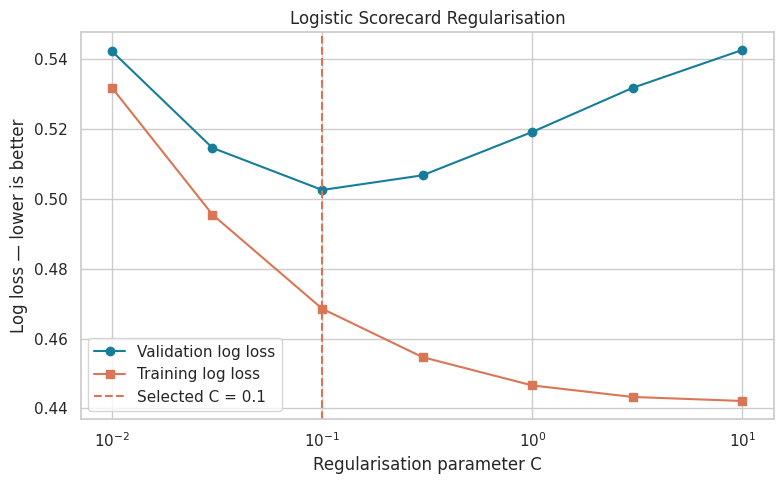

In [ ]:
# ============================================================
# STEP 33: PLOT REGULARISATION RESULTS
# ============================================================

plot_results = (
    cv_results_table
    .sort_values("param_model__C")
)

plt.figure(figsize=(8, 5))

plt.semilogx(
    plot_results[
        "param_model__C"
    ].astype(float),
    plot_results[
        "Mean_validation_log_loss"
    ],
    marker="o",
    label="Validation log loss"
)

plt.semilogx(
    plot_results[
        "param_model__C"
    ].astype(float),
    plot_results[
        "Mean_train_log_loss"
    ],
    marker="s",
    label="Training log loss"
)

plt.axvline(
    best_c,
    color="#DA7655",
    linestyle="--",
    label=f"Selected C = {best_c}"
)

plt.xlabel(
    "Regularisation parameter C"
)

plt.ylabel(
    "Log loss — lower is better"
)

plt.title(
    "Logistic Scorecard Regularisation"
)

plt.legend()

finish_member2_plot(
    "01_regularisation_selection"
)

In [ ]:
# ============================================================
# STEP 34: GENERATE OOF PROBABILITIES
# ============================================================

oof_probability = cross_val_predict(
    best_scorecard,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

assert len(oof_probability) == 800

assert np.all(
    (oof_probability >= 0)
    & (oof_probability <= 1)
)

oof_metrics = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Brier score"
    ],
    "Value": [
        roc_auc_score(
            y_train,
            oof_probability
        ),
        average_precision_score(
            y_train,
            oof_probability
        ),
        brier_score_loss(
            y_train,
            oof_probability
        )
    ]
})

save_member2_table(
    oof_metrics,
    "05_oof_training_metrics",
    index=False
)

,Metric,Value
0,ROC-AUC,0.779
1,PR-AUC,0.599
2,Brier score,0.167


In [ ]:
# ============================================================
# STEP 35: DEFINE UCI DECISION COSTS
# ============================================================

# Cost of incorrectly predicting a good customer
# as bad risk, potentially causing a good customer
# to be rejected.
COST_REJECT_GOOD = 1

# Cost of incorrectly predicting a bad customer
# as good risk, potentially causing a bad customer
# to be approved.
COST_APPROVE_BAD = 5

assert COST_REJECT_GOOD > 0
assert COST_APPROVE_BAD > 0

assert (
    COST_APPROVE_BAD
    > COST_REJECT_GOOD
)

print("UCI decision costs defined.")
print(
    "Rejecting a good customer:",
    COST_REJECT_GOOD,
    "cost unit"
)
print(
    "Approving a bad customer:",
    COST_APPROVE_BAD,
    "cost units"
)

UCI decision costs defined.
Rejecting a good customer: 1 cost unit
Approving a bad customer: 5 cost units


In [ ]:
# ============================================================
# STEP 36: SELECT COST-SENSITIVE THRESHOLD
# ============================================================

thresholds = np.arange(
    0.05,
    0.951,
    0.005
)

threshold_results = []

for threshold in thresholds:
    predicted_bad = (
        oof_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predicted_bad,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        COST_REJECT_GOOD * fp
        + COST_APPROVE_BAD * fn
    )

    recall_bad = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_good = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    approval_rate = (
        predicted_bad == 0
    ).mean()

    threshold_results.append({
        "Threshold": threshold,
        "Total_cost": total_cost,
        "Cost_per_100_customers":
            total_cost / len(y_train) * 100,
        "Recall_bad_risk": recall_bad,
        "Specificity_good_risk":
            specificity_good,
        "Approval_rate": approval_rate,
        "Rejected_good_customers":
            int(fp),
        "Approved_bad_customers":
            int(fn)
    })

threshold_table = pd.DataFrame(
    threshold_results
)

best_threshold_row = threshold_table.loc[
    threshold_table[
        "Total_cost"
    ].idxmin()
]

selected_threshold = float(
    best_threshold_row["Threshold"]
)

save_member2_table(
    threshold_table,
    "06_oof_threshold_search",
    index=False
)

print(
    "Selected threshold:",
    round(selected_threshold, 3)
)

display(
    best_threshold_row.to_frame(
        "Selected policy"
    )
)

,Threshold,Total_cost,Cost_per_100_customers,Recall_bad_risk,Specificity_good_risk,Approval_rate,Rejected_good_customers,Approved_bad_customers
0,0.050,533,66.625,0.996,0.057,0.041,528,1
1,0.055,528,66.000,0.996,0.066,0.048,523,1
2,0.060,519,64.875,0.996,0.082,0.059,514,1
3,0.065,517,64.625,0.992,0.095,0.069,507,2
4,0.070,508,63.500,0.992,0.111,0.080,498,2
...,...,...,...,...,...,...,...,...
176,0.930,1200,150.000,0.000,1.000,1.000,0,240
177,0.935,1200,150.000,0.000,1.000,1.000,0,240
178,0.940,1200,150.000,0.000,1.000,1.000,0,240
179,0.945,1200,150.000,0.000,1.000,1.000,0,240


Selected threshold: 0.19


,Selected policy
Threshold,0.190
Total_cost,404.000
Cost_per_100_customers,50.500
Recall_bad_risk,0.908
Specificity_good_risk,0.475
Approval_rate,0.360
Rejected_good_customers,294.000
Approved_bad_customers,22.000


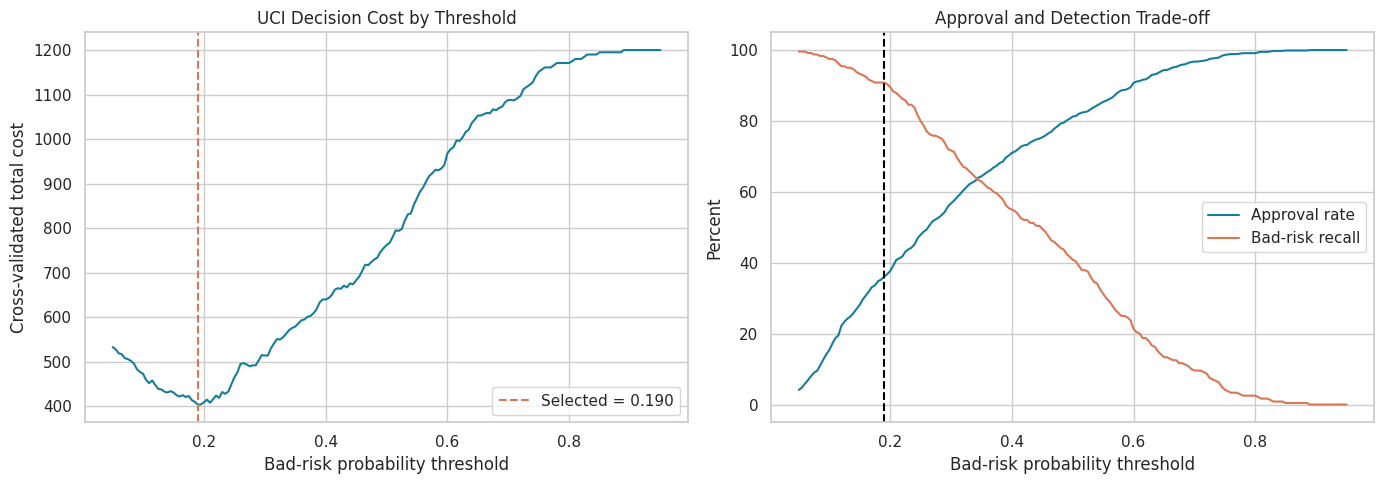

In [ ]:
# ============================================================
# STEP 37: PLOT THRESHOLD RESULTS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    threshold_table["Threshold"],
    threshold_table["Total_cost"],
    color="#167D9A"
)

axes[0].axvline(
    selected_threshold,
    color="#DA7655",
    linestyle="--",
    label=(
        f"Selected = "
        f"{selected_threshold:.3f}"
    )
)

axes[0].set_title(
    "UCI Decision Cost by Threshold"
)

axes[0].set_xlabel(
    "Bad-risk probability threshold"
)

axes[0].set_ylabel(
    "Cross-validated total cost"
)

axes[0].legend()

axes[1].plot(
    threshold_table["Threshold"],
    threshold_table[
        "Approval_rate"
    ] * 100,
    label="Approval rate",
    color="#167D9A"
)

axes[1].plot(
    threshold_table["Threshold"],
    threshold_table[
        "Recall_bad_risk"
    ] * 100,
    label="Bad-risk recall",
    color="#DA7655"
)

axes[1].axvline(
    selected_threshold,
    color="black",
    linestyle="--"
)

axes[1].set_title(
    "Approval and Detection Trade-off"
)

axes[1].set_xlabel(
    "Bad-risk probability threshold"
)

axes[1].set_ylabel("Percent")
axes[1].legend()

finish_member2_plot(
    "02_threshold_cost_analysis"
)

In [ ]:
# ============================================================
# STEP 38: FIT FINAL SCORECARD
# ============================================================

best_scorecard.fit(
    X_train,
    y_train
)

train_probability = (
    best_scorecard.predict_proba(
        X_train
    )[:, 1]
)

test_probability = (
    best_scorecard.predict_proba(
        X_test
    )[:, 1]
)

default_test_prediction = (
    test_probability >= 0.50
).astype(int)

cost_test_prediction = (
    test_probability
    >= selected_threshold
).astype(int)

print(
    "Final scorecard fitted using "
    "all 800 training customers."
)

Final scorecard fitted using all 800 training customers.


In [ ]:
# ============================================================
# STEP 39: DEFINE EVALUATION FUNCTION
# ============================================================

def evaluate_policy(
    actual,
    probability,
    predicted,
    policy_name,
    threshold
):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    approval_mask = (
        predicted == 0
    )

    approval_rate = (
        approval_mask.mean()
    )

    bad_rate_among_approved = (
        actual[approval_mask].mean()
        if approval_mask.sum() > 0
        else np.nan
    )

    total_cost = (
        COST_REJECT_GOOD * fp
        + COST_APPROVE_BAD * fn
    )

    return {
        "Policy": policy_name,
        "Threshold": threshold,
        "ROC_AUC": roc_auc_score(
            actual,
            probability
        ),
        "PR_AUC": average_precision_score(
            actual,
            probability
        ),
        "Accuracy": accuracy_score(
            actual,
            predicted
        ),
        "Balanced_accuracy":
            balanced_accuracy_score(
                actual,
                predicted
            ),
        "Precision_bad_risk":
            precision_score(
                actual,
                predicted,
                zero_division=0
            ),
        "Recall_bad_risk":
            recall_score(
                actual,
                predicted,
                zero_division=0
            ),
        "Specificity_good_risk":
            specificity,
        "F1_bad_risk":
            f1_score(
                actual,
                predicted,
                zero_division=0
            ),
        "Brier_score":
            brier_score_loss(
                actual,
                probability
            ),
        "Approval_rate":
            approval_rate,
        "Bad_rate_among_approved":
            bad_rate_among_approved,
        "Rejected_good_customers":
            int(fp),
        "Approved_bad_customers":
            int(fn),
        "UCI_total_cost":
            float(total_cost),
        "UCI_cost_per_100":
            total_cost / len(actual) * 100
    }

In [ ]:
# ============================================================
# STEP 40: FINAL TEST EVALUATION
# ============================================================

default_metrics = evaluate_policy(
    y_test,
    test_probability,
    default_test_prediction,
    "Default threshold",
    0.50
)

cost_metrics = evaluate_policy(
    y_test,
    test_probability,
    cost_test_prediction,
    "Cost-sensitive threshold",
    selected_threshold
)

test_metrics = pd.DataFrame([
    default_metrics,
    cost_metrics
])

save_member2_table(
    test_metrics,
    "07_final_test_metrics",
    index=False
)

print(
    "Test evaluation completed. "
    "The test data were not used to select "
    "the model or threshold."
)

,Policy,Threshold,ROC_AUC,PR_AUC,Accuracy,Balanced_accuracy,Precision_bad_risk,Recall_bad_risk,Specificity_good_risk,F1_bad_risk,Brier_score,Approval_rate,Bad_rate_among_approved,Rejected_good_customers,Approved_bad_customers,UCI_total_cost,UCI_cost_per_100
0,Default threshold,0.500,0.787,0.621,0.740,0.638,0.605,0.383,0.893,0.469,0.161,0.810,0.228,15,37,200.000,100.000
1,Cost-sensitive threshold,0.190,0.787,0.621,0.575,0.654,0.402,0.850,0.457,0.545,0.161,0.365,0.123,76,9,121.000,60.500


Test evaluation completed. The test data were not used to select the model or threshold.


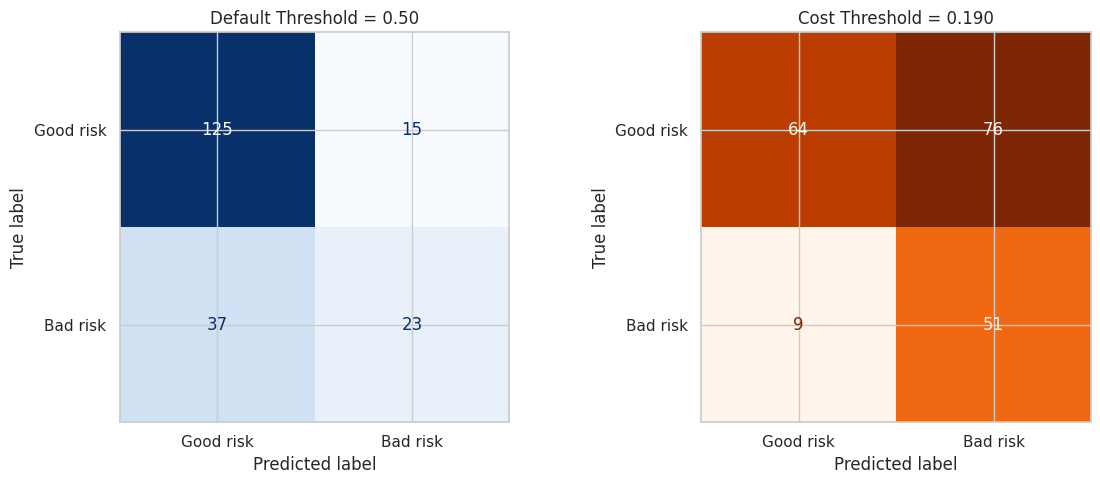

In [ ]:
# ============================================================
# STEP 41: CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    default_test_prediction,
    display_labels=[
        "Good risk",
        "Bad risk"
    ],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title(
    "Default Threshold = 0.50"
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    cost_test_prediction,
    display_labels=[
        "Good risk",
        "Bad risk"
    ],
    cmap="Oranges",
    colorbar=False,
    ax=axes[1]
)

axes[1].set_title(
    f"Cost Threshold = "
    f"{selected_threshold:.3f}"
)

finish_member2_plot(
    "03_test_confusion_matrices"
)

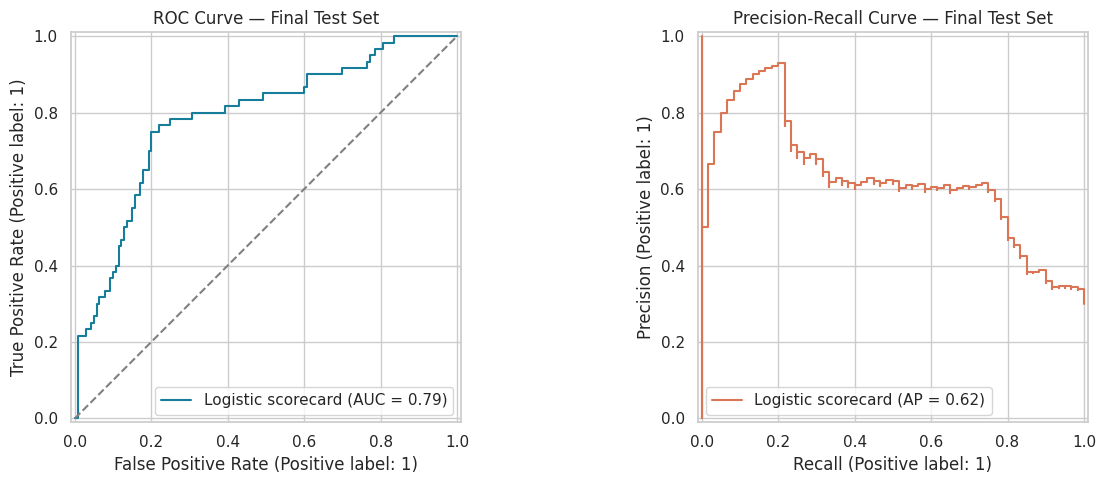

In [ ]:
# ============================================================
# STEP 42: DISCRIMINATION CURVES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

RocCurveDisplay.from_predictions(
    y_test,
    test_probability,
    name="Logistic scorecard",
    color="#167D9A",
    ax=axes[0]
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey"
)

axes[0].set_title(
    "ROC Curve — Final Test Set"
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probability,
    name="Logistic scorecard",
    color="#DA7655",
    ax=axes[1]
)

axes[1].set_title(
    "Precision-Recall Curve — Final Test Set"
)

finish_member2_plot(
    "04_test_discrimination_curves"
)

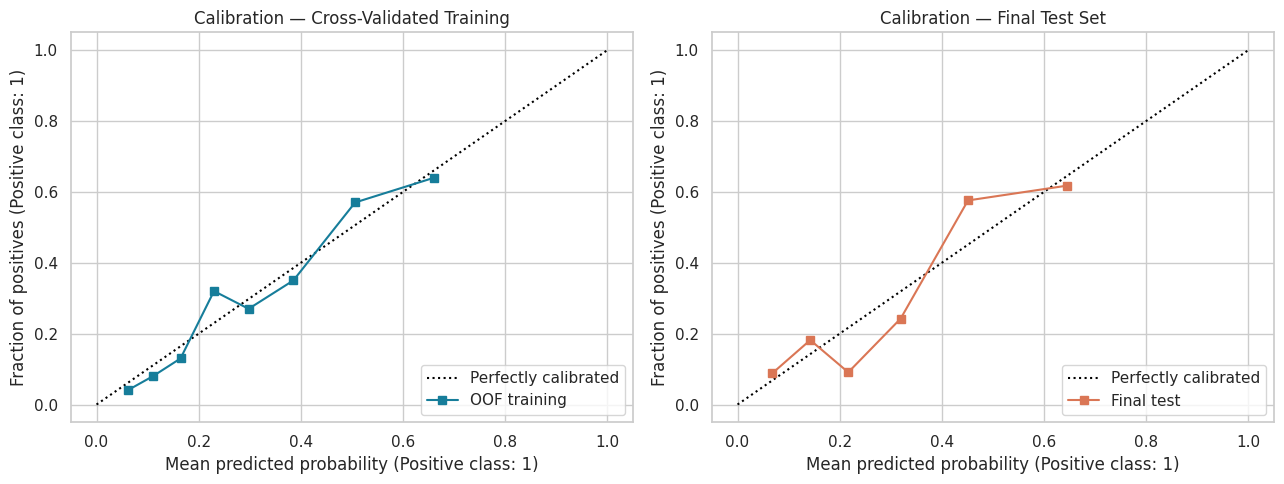

In [ ]:
# ============================================================
# STEP 43: CALIBRATION ANALYSIS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

CalibrationDisplay.from_predictions(
    y_train,
    oof_probability,
    n_bins=8,
    strategy="quantile",
    name="OOF training",
    color="#167D9A",
    ax=axes[0]
)

axes[0].set_title(
    "Calibration — Cross-Validated Training"
)

CalibrationDisplay.from_predictions(
    y_test,
    test_probability,
    n_bins=6,
    strategy="quantile",
    name="Final test",
    color="#DA7655",
    ax=axes[1]
)

axes[1].set_title(
    "Calibration — Final Test Set"
)

finish_member2_plot(
    "05_calibration_curves"
)

In [ ]:
# ============================================================
# STEP 44: EXTRACT SCORECARD COEFFICIENTS
# ============================================================

fitted_preprocessor = (
    best_scorecard
    .named_steps["preprocessor"]
)

fitted_logistic = (
    best_scorecard
    .named_steps["model"]
)

encoded_feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

coefficients = pd.DataFrame({
    "Encoded_feature":
        encoded_feature_names,
    "Coefficient":
        fitted_logistic.coef_[0]
})

coefficients["Odds_ratio"] = np.exp(
    coefficients["Coefficient"]
)

coefficients[
    "Absolute_coefficient"
] = coefficients[
    "Coefficient"
].abs()

coefficients[
    "Risk_direction"
] = np.where(
    coefficients["Coefficient"] > 0,
    "Higher bad-risk odds",
    "Lower bad-risk odds"
)

coefficients = (
    coefficients
    .sort_values(
        "Absolute_coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

save_member2_table(
    coefficients,
    "08_scorecard_coefficients",
    index=False
)

print(
    "Model intercept:",
    fitted_logistic.intercept_[0]
)

,Encoded_feature,Coefficient,Odds_ratio,Absolute_coefficient,Risk_direction
0,categorical__checking_status_no_checking_account,-0.866,0.420,0.866,Lower bad-risk odds
1,categorical__credit_history_critical_account_o...,-0.591,0.554,0.591,Lower bad-risk odds
2,categorical__other_installment_plans_none,-0.485,0.616,0.485,Lower bad-risk odds
3,log_numeric__duration_months,0.464,1.590,0.464,Higher bad-risk odds
4,categorical__purpose_used_car,-0.436,0.647,0.436,Lower bad-risk odds
5,categorical__savings_status_unknown_or_no_savings,-0.389,0.678,0.389,Lower bad-risk odds
6,categorical__purpose_education,0.388,1.475,0.388,Higher bad-risk odds
7,categorical__employment_duration_less_than_1_year,0.376,1.456,0.376,Higher bad-risk odds
8,categorical__checking_status_less_than_0_DM,0.355,1.427,0.355,Higher bad-risk odds
9,categorical__savings_status_less_than_100_DM,0.347,1.415,0.347,Higher bad-risk odds


Model intercept: -0.1448769800373211


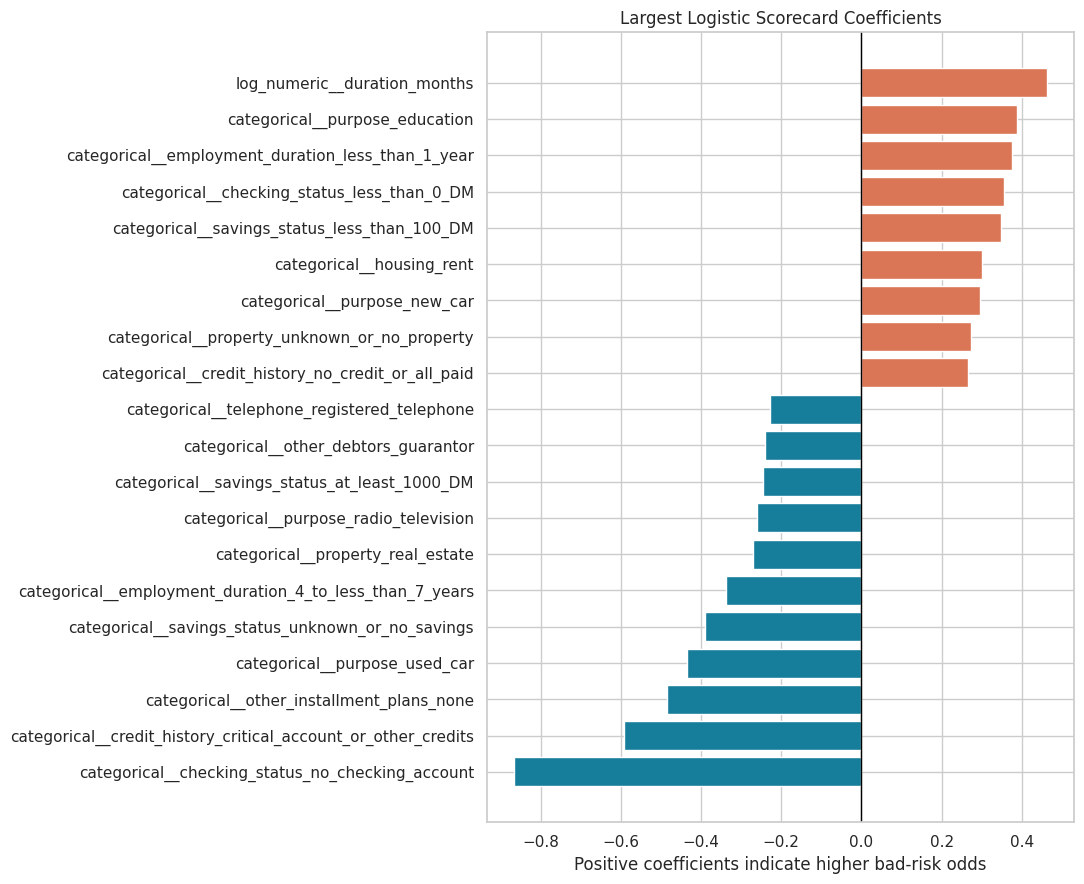

In [ ]:
# ============================================================
# STEP 45: PLOT SCORECARD COEFFICIENTS
# ============================================================

top_coefficients = (
    coefficients
    .head(20)
    .sort_values("Coefficient")
)

bar_colours = np.where(
    top_coefficients[
        "Coefficient"
    ] > 0,
    "#DA7655",
    "#167D9A"
)

plt.figure(figsize=(11, 9))

plt.barh(
    top_coefficients[
        "Encoded_feature"
    ],
    top_coefficients[
        "Coefficient"
    ],
    color=bar_colours
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Largest Logistic Scorecard Coefficients"
)

plt.xlabel(
    "Positive coefficients indicate "
    "higher bad-risk odds"
)

plt.ylabel("")

finish_member2_plot(
    "06_scorecard_coefficients"
)

In [ ]:
# ============================================================
# STEP 46: CONVERT PROBABILITIES TO ILLUSTRATIVE CREDIT SCORES
# ============================================================

BASE_SCORE = 600
BASE_ODDS_GOOD_TO_BAD = 20
POINTS_TO_DOUBLE_ODDS = 50

factor = POINTS_TO_DOUBLE_ODDS / np.log(2)

offset = (
    BASE_SCORE
    - factor * np.log(BASE_ODDS_GOOD_TO_BAD)
)

def probability_to_score(probability_bad):

    probability_bad = np.clip(
        np.asarray(probability_bad),
        1e-6,
        1 - 1e-6
    )

    odds_good_to_bad = (
        (1 - probability_bad)
        / probability_bad
    )

    score = (
        offset
        + factor * np.log(odds_good_to_bad)
    )

    return np.round(score).astype(int)

# Use out-of-fold probabilities for training observations.
oof_train_score = probability_to_score(
    oof_probability
)

test_score = probability_to_score(
    test_probability
)

score_summary = pd.DataFrame({
    "Dataset": [
        "OOF training scores",
        "Test scores"
    ],
    "Minimum": [
        oof_train_score.min(),
        test_score.min()
    ],
    "Median": [
        np.median(oof_train_score),
        np.median(test_score)
    ],
    "Maximum": [
        oof_train_score.max(),
        test_score.max()
    ]
})

display(score_summary)

print(
    "Higher illustrative scores represent lower "
    "predicted bad-risk probability."
)

,Dataset,Minimum,Median,Maximum
0,OOF training scores,236,458.000,695
1,Test scores,262,458.500,684


Higher illustrative scores represent lower predicted bad-risk probability.


In [ ]:
# ============================================================
# STEP 47: CREATE RISK BANDS FROM OOF TRAINING SCORES
# ============================================================

_, score_boundaries = pd.qcut(
    oof_train_score,
    q=4,
    retbins=True,
    duplicates="drop"
)

score_boundaries[0] = -np.inf
score_boundaries[-1] = np.inf

risk_labels = [
    "Very high risk",
    "High risk",
    "Medium risk",
    "Low risk"
]

oof_train_risk_band = pd.cut(
    oof_train_score,
    bins=score_boundaries,
    labels=risk_labels,
    include_lowest=True
)

test_risk_band = pd.cut(
    test_score,
    bins=score_boundaries,
    labels=risk_labels,
    include_lowest=True
)

risk_band_summary = (
    pd.DataFrame({
        "Risk_band": test_risk_band,
        "bad_risk": y_test.to_numpy()
    })
    .groupby(
        "Risk_band",
        observed=False
    )["bad_risk"]
    .agg(
        Customers="size",
        Bad_risk_cases="sum",
        Observed_bad_risk_rate="mean"
    )
    .reset_index()
)

risk_band_summary[
    "Observed_bad_risk_percent"
] = (
    risk_band_summary[
        "Observed_bad_risk_rate"
    ] * 100
).round(1)

display(risk_band_summary)

print(
    "Risk-band boundaries were derived from "
    "out-of-fold training scores only."
)

,Risk_band,Customers,Bad_risk_cases,Observed_bad_risk_rate,Observed_bad_risk_percent
0,Very high risk,54,33,0.611,61.100
1,High risk,46,15,0.326,32.600
2,Medium risk,55,7,0.127,12.700
3,Low risk,45,5,0.111,11.100


Risk-band boundaries were derived from out-of-fold training scores only.


In [ ]:
# ============================================================
# STEP 48: SUMMARISE TEST RISK BANDS
# ============================================================

risk_band_test_data = pd.DataFrame({
    "Risk_band":
        test_risk_band,
    "Actual_bad_risk":
        y_test.to_numpy(),
    "Predicted_bad_probability":
        test_probability,
    "Credit_score":
        test_score
})

risk_band_summary = (
    risk_band_test_data
    .groupby(
        "Risk_band",
        observed=True
    )
    .agg(
        Customers=(
            "Actual_bad_risk",
            "size"
        ),
        Actual_bad_cases=(
            "Actual_bad_risk",
            "sum"
        ),
        Actual_bad_rate=(
            "Actual_bad_risk",
            "mean"
        ),
        Mean_predicted_bad_probability=(
            "Predicted_bad_probability",
            "mean"
        ),
        Minimum_score=(
            "Credit_score",
            "min"
        ),
        Maximum_score=(
            "Credit_score",
            "max"
        )
    )
    .reset_index()
)

risk_band_summary[
    "Actual_bad_rate_percent"
] = (
    risk_band_summary[
        "Actual_bad_rate"
    ] * 100
)

risk_band_summary[
    "Mean_predicted_bad_probability_percent"
] = (
    risk_band_summary[
        "Mean_predicted_bad_probability"
    ] * 100
)

save_member2_table(
    risk_band_summary,
    "11_test_risk_band_summary",
    index=False
)

,Risk_band,Customers,Actual_bad_cases,Actual_bad_rate,Mean_predicted_bad_probability,Minimum_score,Maximum_score,Actual_bad_rate_percent,Mean_predicted_bad_probability_percent
0,Very high risk,54,33,0.611,0.582,262,400,61.111,58.232
1,High risk,46,15,0.326,0.346,402,457,32.609,34.627
2,Medium risk,55,7,0.127,0.191,460,517,12.727,19.085
3,Low risk,45,5,0.111,0.081,519,684,11.111,8.144


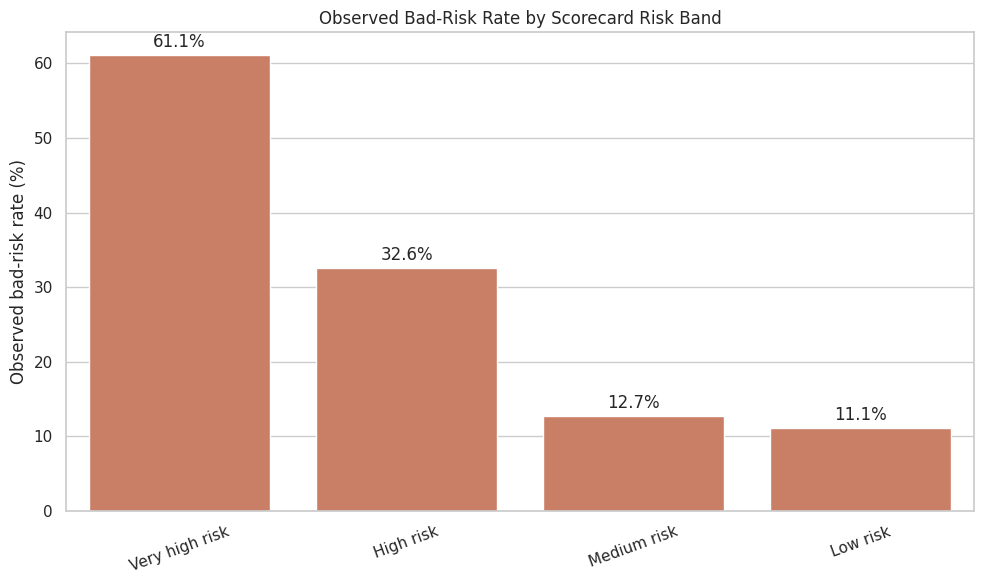

In [ ]:
# ============================================================
# STEP 49: PLOT RISK-BAND OUTCOMES
# ============================================================

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=risk_band_summary,
    x="Risk_band",
    y="Actual_bad_rate_percent",
    color="#DA7655"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.title(
    "Observed Bad-Risk Rate by Scorecard Risk Band"
)

plt.xlabel("")
plt.ylabel(
    "Observed bad-risk rate (%)"
)

plt.xticks(rotation=20)

finish_member2_plot(
    "07_risk_band_bad_rates"
)

In [ ]:
# ============================================================
# STEP 50: EXPORT TEST PREDICTIONS
# ============================================================

test_predictions = pd.DataFrame({
    "customer_id":
        test_df[
            "customer_id"
        ].to_numpy(),

    "actual_bad_risk":
        y_test.to_numpy(),

    "predicted_bad_probability":
        test_probability,

    "predicted_bad_default_threshold":
        default_test_prediction,

    "predicted_bad_cost_threshold":
        cost_test_prediction,

    "approval_default_threshold":
        np.where(
            default_test_prediction == 0,
            "Approve",
            "Decline"
        ),

    "approval_cost_threshold":
        np.where(
            cost_test_prediction == 0,
            "Approve",
            "Decline"
        ),

    "credit_score":
        test_score,

    "risk_band":
        test_risk_band.astype(str),

    "sex_audit":
        test_df[
            "sex_audit"
        ].astype(str).to_numpy(),

    "age_group_audit":
        test_df[
            "age_group_audit"
        ].astype(str).to_numpy()
})

test_predictions.to_csv(
    MEMBER2_DATA
    / "member2_test_predictions.csv",
    index=False
)

display(test_predictions.head())

print(
    "Test predictions exported for "
    "Members 3 and 4."
)

,customer_id,actual_bad_risk,predicted_bad_probability,predicted_bad_default_threshold,predicted_bad_cost_threshold,approval_default_threshold,approval_cost_threshold,credit_score,risk_band,sex_audit,age_group_audit
0,31,0,0.331,0,1,Approve,Decline,435,High risk,male,25_to_44
1,129,0,0.178,0,0,Approve,Approve,494,Medium risk,male,25_to_44
2,290,1,0.594,1,1,Decline,Decline,356,Very high risk,male,45_and_over
3,217,0,0.511,1,1,Decline,Decline,381,Very high risk,male,25_to_44
4,967,1,0.243,0,1,Approve,Decline,466,Medium risk,male,under_25


Test predictions exported for Members 3 and 4.


In [ ]:
# ============================================================
# STEP 51: EXPORT OOF TRAINING PREDICTIONS
# ============================================================

oof_training_predictions = pd.DataFrame({
    "customer_id":
        train_df[
            "customer_id"
        ].to_numpy(),

    "actual_bad_risk":
        y_train.to_numpy(),

    "oof_predicted_bad_probability":
        oof_probability,

    "oof_cost_threshold_prediction":
        (
            oof_probability
            >= selected_threshold
        ).astype(int),

    "sex_audit":
        train_df[
            "sex_audit"
        ].astype(str).to_numpy(),

    "age_group_audit":
        train_df[
            "age_group_audit"
        ].astype(str).to_numpy()
})

oof_training_predictions[
    "oof_approval_decision"
] = np.where(
    oof_training_predictions[
        "oof_cost_threshold_prediction"
    ] == 0,
    "Approve",
    "Decline"
)

oof_training_predictions.to_csv(
    MEMBER2_DATA
    / "member2_oof_training_predictions.csv",
    index=False
)

display(
    oof_training_predictions.head()
)

,customer_id,actual_bad_risk,oof_predicted_bad_probability,oof_cost_threshold_prediction,sex_audit,age_group_audit,oof_approval_decision
0,829,1,0.393,1,male,45_and_over,Decline
1,998,0,0.122,0,male,25_to_44,Approve
2,149,0,0.401,1,male,25_to_44,Decline
3,736,0,0.671,1,female,25_to_44,Decline
4,131,0,0.339,1,female,under_25,Decline


In [ ]:
# ============================================================
# STEP 52: SAVE MODEL AND POLICY
# ============================================================

joblib.dump(
    best_scorecard,
    MEMBER2_MODELS
    / "logistic_scorecard_pipeline.joblib"
)

decision_policy = {
    "target": "bad_risk",
    "selected_C": best_c,
    "default_threshold": 0.50,
    "cost_sensitive_threshold":
        selected_threshold,
    "cost_reject_good":
        COST_REJECT_GOOD,
    "cost_approve_bad":
        COST_APPROVE_BAD,
    "base_score":
        BASE_SCORE,
    "base_good_to_bad_odds":
        BASE_ODDS_GOOD_TO_BAD,
    "points_to_double_odds":
        POINTS_TO_DOUBLE_ODDS,
    "protected_source_excluded":
        "personal_status_sex",
    "age_included_in_primary_model":
        True,
    "training_rows":
        len(X_train),
    "test_rows":
        len(X_test),
    "random_seed":
        SEED
}

with open(
    MEMBER2_MODELS
    / "decision_policy.json",
    "w"
) as file:
    json.dump(
        decision_policy,
        file,
        indent=2
    )

print(
    "Scorecard pipeline and decision "
    "policy saved."
)

Scorecard pipeline and decision policy saved.


In [ ]:
# ============================================================
# STEP 53: FINAL INTEGRITY CHECKS
# ============================================================

assert len(test_predictions) == 200

assert test_predictions[
    "customer_id"
].is_unique

assert test_predictions[
    "predicted_bad_probability"
].between(0, 1).all()

assert not set(
    forbidden_columns
).intersection(model_features)

assert (
    "personal_status_sex"
    not in model_features
)

assert (
    MEMBER2_MODELS
    / "logistic_scorecard_pipeline.joblib"
).exists()

assert (
    MEMBER2_MODELS
    / "decision_policy.json"
).exists()

assert len(oof_training_predictions) == 800

assert oof_training_predictions[
    "customer_id"
].is_unique

assert oof_training_predictions[
    "oof_predicted_bad_probability"
].between(0, 1).all()

assert (
    MEMBER2_DATA
    / "member2_test_predictions.csv"
).exists()

assert (
    MEMBER2_DATA
    / "member2_oof_training_predictions.csv"
).exists()

print("All Member 2 integrity checks passed.")
print("Member 2 coding section is complete.")

All Member 2 integrity checks passed.
Member 2 coding section is complete.


In [ ]:
# ============================================================
# MEMBER 2 CHECKPOINT
# ============================================================

print("Member 2 section completed.")
print("Selected logistic C:", best_c)

print(
    "Selected cost-sensitive threshold:",
    round(selected_threshold, 3)
)

print("\nFinal test results:")
display(test_metrics)

print("\nFiles available for later members:")

print(
    MEMBER2_DATA
    / "member2_test_predictions.csv"
)

print(
    MEMBER2_DATA
    / "member2_oof_training_predictions.csv"
)

print(
    MEMBER2_MODELS
    / "logistic_scorecard_pipeline.joblib"
)

print(
    MEMBER2_MODELS
    / "decision_policy.json"
)

Member 2 section completed.
Selected logistic C: 0.1
Selected cost-sensitive threshold: 0.19

Final test results:


,Policy,Threshold,ROC_AUC,PR_AUC,Accuracy,Balanced_accuracy,Precision_bad_risk,Recall_bad_risk,Specificity_good_risk,F1_bad_risk,Brier_score,Approval_rate,Bad_rate_among_approved,Rejected_good_customers,Approved_bad_customers,UCI_total_cost,UCI_cost_per_100
0,Default threshold,0.500,0.787,0.621,0.740,0.638,0.605,0.383,0.893,0.469,0.161,0.810,0.228,15,37,200.000,100.000
1,Cost-sensitive threshold,0.190,0.787,0.621,0.575,0.654,0.402,0.850,0.457,0.545,0.161,0.365,0.123,76,9,121.000,60.500



Files available for later members:
member2_scorecard_outputs/data/member2_test_predictions.csv
member2_scorecard_outputs/data/member2_oof_training_predictions.csv
member2_scorecard_outputs/models/logistic_scorecard_pipeline.joblib
member2_scorecard_outputs/models/decision_policy.json


## Shu Ru - Member 3

## Thiri - Member 4